# Notebook 11 — Final research consolidation: tables, figures and records for the DSC 501 article (no new experiments)

**What this notebook does:** reads the saved results of Notebooks 1–10 and 8b, **checks** them, and exports
publication-ready tables (CSV + LaTeX) and figures (vector PDF + 300-DPI PNG), plus an index of every file.

**What it does NOT do:** no model training, no new datasets, no architecture changes, no new hypothesis tests, no model
selection, and **no manuscript prose** (faculty rule: the article must be student-written). LaTeX tables carry a
placeholder caption for you to write. Earlier result folders are only read; everything is written to `final_v11/`.

**Statistics are preserved, not redone.** Every effect, 95 % interval, p-value and Holm-adjusted p-value is copied from the
notebook that ran the test, together with the name of its test family. The only numbers computed here are
*descriptive* (means, standard deviations, a descriptive 95 % interval of a single model's score from a seed + cluster
bootstrap, confusion matrices, calibration bins) plus **one post-hoc Holm adjustment of NB7's saved raw p-values**, because
NB7's pre-registered rule had no multiplicity correction. It is labelled post hoc wherever it appears; no new test is run.

**Sample order.** Matching label arrays do not prove the same samples in the same order, so saved sample identifiers are
compared wherever they exist (MOSEI/MOSI `test_ids.csv`, the MOSI data file). Where none were saved (Amazon and text-dataset
prediction files), the basis for the order is stated in table R05 and in the limitations.

**Evidence labels used in every table**
| Label | Meaning |
|---|---|
| Supported | A test fixed in advance: Holm-adjusted p < .05 and \|effect\| ≥ 1 pp (verdict HELPS / HURTS); for NB7's checks (no correction in NB7's rule): check met **and** post-hoc Holm p < .05 over all NB7 checks |
| Nominal only | NB7 check met without correction (CI excludes 0) but not significant after the post-hoc Holm correction |
| Bounded (CI within ±1 pp) | The pre-registered "negligible" verdict: the 95 % interval lies inside ±1 pp. **Not a formal equivalence test.** |
| Inconclusive | Tested, no detectable effect; the interval still allows effects of 1 pp or more. **Not evidence of no effect.** |
| Exploratory | Tested on the repeatedly used MOSEI test set without pre-registration and without multiplicity correction (Notebooks 3–6) |
| Descriptive | Measured, not tested (means, parameter counts, latency, shares) |
| Hypothesis | A proposed explanation; no causal test was run |

**Runtime: CPU** is enough (a few minutes on the test copies; reading the MOSI data file and the NB8 predictions from Drive adds load time). If a source file is missing or inconsistent, the notebook reports it in the
validation table and skips only the outputs that need it — it never substitutes a value.

In [1]:
import os, re, sys, json, glob, time, hashlib, platform, pickle, warnings
IN_COLAB = "google.colab" in sys.modules
TEST_MODE = os.environ.get("EMOFAR_TEST") == "1"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
warnings.filterwarnings("ignore", category=FutureWarning)

Mounted at /content/drive


## 1. Settings, sources (read only) and output folders

In [2]:
BASE = "/content/drive/MyDrive/emofar_results"
DATA_ROOT = "/content/drive/MyDrive/datasets"
if TEST_MODE:
    BASE, DATA_ROOT = os.environ["EMOFAR_BASE"], os.environ.get("EMOFAR_DATA", "")
SRC = {"NB1": BASE, "NB2": f"{BASE}/mosei_v2_cpu", "NB3": f"{BASE}/mosei_v3_diagnostics", "NB4": f"{BASE}/mosei_v4_capacity_utility",
       "NB5": f"{BASE}/mosei_v5_representation_diagnostics", "NB6": f"{BASE}/mosei_v6_head_vs_exposure", "NB7": f"{BASE}/mosi_v7_confirmation",
       "NB8": f"{BASE}/v8_ablations", "NB8b": f"{BASE}/v8_ablations/eq15_check", "NB9": f"{BASE}/amazon_v9", "NB10": f"{BASE}/text_v10"}
OUT = f"{BASE}/final_v11"; FIG, TAB, REC = f"{OUT}/figures", f"{OUT}/tables", f"{OUT}/records"
for d in (FIG, TAB, REC):
    os.makedirs(d, exist_ok=True)
SEEDS = [42, 43, 44]
CONDS = ["T", "A", "V", "A+V", "T+A", "T+V", "T+A+V"]
CKEY = {c: c.replace("+", "p") for c in CONDS}
N_BOOT_DESC = 2000 if not TEST_MODE else 300          # descriptive intervals only (no tests are run here)
EXPECTED_AMAZON_FP = "c3a53bf95269b4f6e8a490d0d85be4f9"
T_START = time.time()

def out_path(*parts):
    p = os.path.join(*parts)
    assert os.path.abspath(p).startswith(os.path.abspath(OUT)), "refusing to write outside final_v11"
    return p

# figure style for the Springer Nature template: single column 84 mm, double column 174 mm
SINGLE, DOUBLE = 3.31, 6.85
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f1f0ec"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]   # validated categorical order
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8,
                     "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "legend.frameon": False,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2, "axes.linewidth": 0.6,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "grid.color": GRID,
                     "grid.linewidth": 0.5, "lines.linewidth": 1.4, "lines.markersize": 5, "figure.dpi": 110, "savefig.dpi": 300})
# colour follows the entity in every figure (never its rank); markers are the secondary encoding
STYLE = {"M2": (PAL[0], "o"), "M4": (PAL[1], "s"), "A2": (PAL[2], "^"), "B3": (PAL[3], "D"), "H2": (PAL[4], "v"),
         "Dedicated": (PAL[5], "P"), "M1": (PAL[6], "X"), "A0": (PAL[7], "*"), "B6": (INK2, "h"), "M3": (PAL[7], "p"), "LF M1+U3": (INK2, "d")}
# 8 slots for 11 entities: entities sharing a colour (M3/A0, M1/H4, B6/LF) never appear in the same figure, and markers always differ

INDEX = []   # one row per exported file group
def save_fig(fig, fid, shows, sources, width="double column"):
    files = []
    for ext in ("pdf", "png"):
        p = out_path(FIG, f"{fid}.{ext}"); fig.savefig(p, bbox_inches="tight", dpi=300, facecolor="white"); files.append(os.path.basename(p))
    INDEX.append({"id": fid, "type": "figure", "files": ", ".join(files), "what_it_shows": shows, "sources": sources, "layout": width})
    plt.show(); plt.close(fig)

LATEX_MAP = {"±": r"$\pm$", "−": r"$-$", "≥": r"$\geq$", "≤": r"$\leq$", "×": r"$\times$", "λ": r"$\lambda$", "→": r"$\rightarrow$", "–": "--", "≈": r"$\approx$"}
def tex_escape(s):
    s = str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"), ("{", r"\{"), ("}", r"\}"),
                 ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}"), ("_", r"\_\allowbreak{}"), ("/", r"/\allowbreak{}")]:
        s = s.replace(a, b)
    for a, b in LATEX_MAP.items():
        s = s.replace(a, b)
    return s

def save_table(df, tid, shows, sources, note=""):
    df = df.reset_index(drop=True)
    df.to_csv(out_path(TAB, f"{tid}.csv"), index=False)
    num = [pd.api.types.is_numeric_dtype(df[c]) for c in df.columns]
    fmt = lambda v: "" if (isinstance(v, float) and np.isnan(v)) else (f"{v:.4g}" if isinstance(v, float) else tex_escape(v))
    vals = [df[c].map(lambda v: fmt(v) if n else str(v)).astype(str) for c, n in zip(df.columns, num)]
    vlen = [int(v.str.len().max()) if len(df) else 0 for v in vals]
    wrap = [(not n) and L > 24 for n, L in zip(num, vlen)]               # long free text wraps; CIs and numbers never do
    natural = sum((max(12, min(L, 26)) if w else max(L, len(str(c)))) + 2 for c, L, w in zip(df.columns, vlen, wrap))
    PAGE = 118                                                            # characters per text width at \scriptsize (conservative)
    X = r">{\raggedright\arraybackslash}X"
    spec = "".join(X if w else ("r" if n else "l") for n, w in zip(num, wrap))
    head = " & ".join(tex_escape(c) for c in df.columns) + r" \\"
    body = [" & ".join(fmt(v) for v in row) + r" \\" for row in df.itertuples(index=False)]
    cap = r"\caption{TODO: write your own caption}\label{tab:" + tid.replace("_", "-") + "}"
    note_line = [r"\par\smallskip{\scriptsize Note: " + tex_escape(note) + r"\par}"] if note else []
    tab = "tabularx" if any(wrap) else "tabular"
    text_heavy = any(wrap) and sum(int(v.str.len().sum()) for v in vals) > 4000   # would not fit one page vertically
    if len(df) > 35 or text_heavy:                                        # breaks across pages; landscape if wide
        env = "xltabular" if any(wrap) else "longtable"
        envspec = (r"{\linewidth}{" + spec + "}") if any(wrap) else ("{" + spec + "}")
        size = r"\scriptsize" if natural <= PAGE * 1.45 else r"\tiny"
        land = natural > PAGE
        lines = ([r"\begin{landscape}"] if land else []) + ["{" + size, rf"\begin{{{env}}}{envspec}", cap + r" \\", r"\toprule", head, r"\midrule",
                 r"\endfirsthead", r"\toprule", head, r"\midrule", r"\endhead", r"\bottomrule", r"\endfoot"] + body + [rf"\end{{{env}}}"] + note_line + \
                ["}"] + ([r"\end{landscape}"] if land else [])
        layout = f"{env}, breaks across pages" + (", landscape (pdflscape)" if land else "")
    else:
        if natural <= PAGE:
            float_, width, box = "table", r"\textwidth", None
        elif natural <= PAGE * 1.45:
            float_, width, box = "sidewaystable", r"\textheight", None
        else:
            float_, width, box = "sidewaystable", f"{natural / (PAGE * 1.45):.2f}\\textheight", r"\textheight"
        tw = ("{" + width + "}") if tab == "tabularx" else ""
        inner = [rf"\begin{{{tab}}}{tw}{{{spec}}}", r"\toprule", head, r"\midrule"] + body + [r"\bottomrule", rf"\end{{{tab}}}"]
        if box:
            inner = [r"\resizebox{" + box + r"}{!}{%"] + inner + ["}"]
        elif tab == "tabular":                                                    # shrink only if wider than the line
            inner = [r"\resizebox{\ifdim\width>\linewidth\linewidth\else\width\fi}{!}{%"] + inner + ["}"]
        lines = [rf"\begin{{{float_}}}" + ("[h]" if float_ == "table" else ""), cap, r"\scriptsize"] + inner + note_line + [rf"\end{{{float_}}}"]
        layout = ("portrait" if float_ == "table" else "landscape (rotating)") + (", scaled to fit" if box else "") + f", {tab}"
    layout += "; preamble: booktabs, tabularx, xltabular, rotating, pdflscape, graphicx"
    open(out_path(TAB, f"{tid}.tex"), "w").write("\n".join(lines) + "\n")
    INDEX.append({"id": tid, "type": "table", "files": f"{tid}.csv, {tid}.tex", "what_it_shows": shows, "sources": sources, "layout": layout})
    with pd.option_context("display.width", 250, "display.max_colwidth", 60):
        print(f"\n{tid}: {shows}"); print(df.to_string(index=False)[:6000])

print("Writing to", OUT, "| test mode" if TEST_MODE else "")

Writing to /content/drive/MyDrive/emofar_results/final_v11 


## 2. Inventory and validation of every source file (before anything is consolidated)
Checks: file exists; required columns; seeds = 42/43/44; model identifiers; units (scores are fractions in [0, 1], effects in pp,
p-values in [0, 1] with Holm p ≥ raw p); label files identical across notebooks that share a test set; prediction arrays match the
label length and are valid probabilities; a saved score recomputed from saved predictions matches the saved table.

In [3]:
VAL, MANIFEST, D, RUN_KEYS = [], [], {}, []
def note(nb, item, status, detail=""):
    VAL.append({"notebook": nb, "item": item, "status": status, "detail": str(detail)[:300]})
    return status == "OK"

def register(nb, path):
    st = os.stat(path); h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    MANIFEST.append({"notebook": nb, "file": os.path.relpath(path, BASE), "bytes": st.st_size, "md5": h.hexdigest(),
                     "modified_utc": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime(st.st_mtime))})

def load(nb, rel, key, kind="csv", cols=None):
    path = os.path.join(SRC[nb], rel)
    if not os.path.exists(path):
        note(nb, rel, "MISSING", path); D[key] = None; return None
    try:
        obj = (pd.read_csv(path) if kind == "csv" else json.load(open(path)) if kind == "json" else np.load(path) if kind == "npy"
               else dict(np.load(path)) if kind == "npz" else pd.read_pickle(path))
    except Exception as e:
        note(nb, rel, "INCONSISTENT", f"cannot be read: {type(e).__name__}: {e}"); D[key] = None; return None
    register(nb, path)
    if kind == "json" and "run_info" in rel:
        RUN_KEYS.append((nb, rel, key))
    if cols is not None:
        miss = [c for c in cols if c not in obj.columns]
        if miss:
            note(nb, rel, "INCONSISTENT", f"missing columns {miss}"); D[key] = None; return None
    note(nb, rel, "OK"); D[key] = obj
    return obj

def check_seeds(nb, key, col="seed"):
    df = D.get(key)
    if df is not None and col in df.columns:
        s = sorted(set(df[col].astype(int)))
        note(nb, f"{key}: seeds", "OK" if s == SEEDS else "INCONSISTENT", s)

def check_frac(nb, key, cols):
    df = D.get(key)
    if df is None:
        return
    for c in cols:
        if c in df.columns:
            v = df[c].dropna()
            note(nb, f"{key}: {c} is a fraction in [0,1]", "OK" if ((v >= 0) & (v <= 1)).all() else "INCONSISTENT", f"range {v.min():.4g}..{v.max():.4g}")

def check_tests(nb, key):
    df = D.get(key)
    if df is None:
        return
    ok = df.p.between(0, 1).all() and df.p_holm.between(0, 1).all() and (df.p_holm + 1e-12 >= df.p).all() and (df.effect_pp.abs() <= 100).all() \
        and (df.lo_pp <= df.effect_pp + 1e-9).all() and (df.hi_pp + 1e-9 >= df.effect_pp).all()
    note(nb, f"{key}: p in [0,1], Holm p >= p, CI contains the effect, effects in pp", "OK" if ok else "INCONSISTENT")

# --- NB1 (superseded single-seed runs; inventory only)
for rel in ["amazon_results_all_seeds.csv", "mosei_results_all_seeds.csv"]:
    p = os.path.join(SRC["NB1"], rel)
    note("NB1", rel, "NOTE", ("present" if os.path.exists(p) else "not found") + "; superseded by NB2/NB9 (v1 runs); not used for any output or claim")
# --- NB2 (MOSEI v2, CPU, 3 seeds)
load("NB2", "main_results_per_seed.csv", "nb2_main", cols=["model", "seed", "macro_f1", "accuracy", "acc2", "ece"]); check_seeds("NB2", "nb2_main")
check_frac("NB2", "nb2_main", ["macro_f1", "accuracy", "acc2", "ece"])
load("NB2", "run_info.json", "nb2_run", "json"); load("NB2", "test_labels.npy", "nb2_y", "npy"); load("NB2", "test_ids.csv", "nb2_ids")
for s in SEEDS:
    load("NB2", f"checkpoints/M1_seed{s}_test_probs.npy", f"nb2_M1_{s}", "npy"); load("NB2", f"checkpoints/M4_seed{s}_log.json", f"nb2_log_M4_{s}", "json")
# --- NB3, NB4, NB5, NB6 (MOSEI diagnostics; exploratory)
load("NB3", "gate_vs_utility.csv", "nb3_gate", cols=["model", "seed", "modality", "mean_gate_weight"]); load("NB3", "integrity_check.csv", "nb3_integrity")
load("NB3", "run_info.json", "nb3_run", "json")
load("NB4", "expA_unimodal_per_seed.csv", "nb4_uni", cols=["model", "seed", "macro_f1"]); check_seeds("NB4", "nb4_uni")
load("NB4", "expA_dedicated_vs_M4_subset.csv", "nb4_tests"); load("NB4", "run_info.json", "nb4_run", "json"); load("NB4", "test_labels.npy", "nb4_y", "npy"); load("NB4", "test_ids.csv", "nb4_ids")
for u in ["U1", "U2", "U3"]:
    for s in SEEDS:
        load("NB4", f"checkpoints/{u}_seed{s}_test_probs.npy", f"nb4_{u}_{s}", "npy")
load("NB5", "R_reference_comparisons.csv", "nb5_ref"); load("NB5", "run_info.json", "nb5_run", "json"); load("NB5", "test_labels.npy", "nb5_y", "npy")
load("NB5", "test_ids.csv", "nb5_ids")
for s in SEEDS:
    load("NB5", f"LF_M1_U3_seed{s}_test_probs.npy", f"nb5_LF_{s}", "npy")
load("NB6", "comparisons.csv", "nb6_cmp", cols=["condition", "comparison", "mean_diff_pp", "per_seed_pp", "sv_lo_pp", "sv_hi_pp", "sv_p"])
load("NB6", "results_per_seed.csv", "nb6_res", cols=["method", "condition", "seed", "test_macro_f1"]); check_seeds("NB6", "nb6_res")
load("NB6", "DECISION.json", "nb6_dec", "json"); load("NB6", "run_info.json", "nb6_run", "json"); load("NB6", "test_labels.npy", "nb6_y", "npy")
load("NB6", "test_ids.csv", "nb6_ids")
for s in SEEDS:
    load("NB6", f"heads/H2_seed{s}_test_probs.npz", f"nb6_H2_{s}", "npz")
if D.get("nb6_dec") is not None:
    note("NB6", "DECISION.json verdict label", "NOTE", "the saved label 'EXPOSURE EXPLAINS IT' is not supported by the numbers (equal exposure added +0.34 pp); "
         "the comparisons are used, the label is not")
# --- NB7 (MOSI confirmation, pre-registered checks)
load("NB7", "checks.csv", "nb7_checks", cols=["check", "condition", "comparison", "mean_diff_pp", "sv_lo_pp", "sv_hi_pp", "sv_p"])
load("NB7", "CONFIRMATION.json", "nb7_conf", "json"); load("NB7", "results_per_seed.csv", "nb7_res", cols=["method", "condition", "seed", "test_macro_f1"])
load("NB7", "models_per_seed.csv", "nb7_models"); load("NB7", "run_info.json", "nb7_run", "json"); load("NB7", "test_labels.npy", "nb7_y", "npy")
load("NB7", "test_ids.csv", "nb7_ids")
check_seeds("NB7", "nb7_res")
for s in SEEDS:
    for m in ["M1", "U1", "U2", "U3"]:
        load("NB7", f"checkpoints/{m}_seed{s}_test_probs.npy", f"nb7_{m}_{s}", "npy")
    load("NB7", f"heads/H2_seed{s}_test_probs.npz", f"nb7_H2_{s}", "npz")
# --- NB8 (ablations) and NB8b (Eq. 15 check)
load("NB8", "per_seed_all_conditions.csv", "nb8_per", cols=["dataset", "model", "seed", "condition", "test_macro_f1"]); check_seeds("NB8", "nb8_per")
check_frac("NB8", "nb8_per", ["test_macro_f1", "test_acc2_nonneutral", "valid_macro_f1"])
load("NB8", "primary_tests.csv", "nb8_prim"); check_tests("NB8", "nb8_prim")
load("NB8", "primary_tests_MOSI_own_holm.csv", "nb8_mosi"); check_tests("NB8", "nb8_mosi")
load("NB8", "secondary_per_condition.csv", "nb8_sec")
NB8_MODELS = ["M2", "M3", "M4", "A0", "A1", "A2", "A3", "A4", "B1", "B2", "B3", "B4", "B5", "B6"]
if D.get("nb8_per") is not None:
    got = set(D["nb8_per"].model)
    note("NB8", "model identifiers", "OK" if got == set(NB8_MODELS) else "INCONSISTENT", sorted(got))
for ds in ["mosei", "mosi"]:
    load("NB8", f"{ds}/parameters.csv", f"nb8_params_{ds}"); load("NB8", f"{ds}/reference_check.json", f"nb8_ref_{ds}", "json")
    load("NB8", f"{ds}/test_labels.npy", f"nb8_y_{ds}", "npy"); load("NB8", f"{ds}/test_scores.npy", f"nb8_score_{ds}", "npy")
    load("NB8", f"{ds}/valid_labels.npy", f"nb8_yv_{ds}", "npy")
    load("NB8", f"{ds}/test_ids.csv", f"nb8_ids_{ds}")
    for m in NB8_MODELS:
        for s in SEEDS:
            load("NB8", f"{ds}/preds/{m}_seed{s}.npz", f"nb8_{ds}_{m}_{s}", "npz")
for p in sorted(glob.glob(f"{SRC['NB8']}/run_info_*.json")):
    load("NB8", os.path.basename(p), f"nb8_run_{os.path.basename(p)}", "json")
load("NB8b", "EQ15_CHECK.json", "nb8b_check", "json")
for d_ in sorted(glob.glob(f"{SRC['NB8']}/eq15_check*")):
    if os.path.isdir(d_) and os.path.basename(d_) != "eq15_check":
        note("NB8b", f"older folder '{os.path.basename(d_)}'", "NOTE", "earlier Eq. 15 check kept by the user; not read; only v8_ablations/eq15_check is used")
for f_, k in [("MOSEI_representations.csv", "nb8b_rep_MOSEI"), ("MOSI_representations.csv", "nb8b_rep_MOSI"), ("MOSEI_classifier_input.csv", "nb8b_h_MOSEI"),
              ("MOSI_classifier_input.csv", "nb8b_h_MOSI"), ("predicted_class_shares.csv", "nb8b_shares"), ("load_checks.csv", "nb8b_load")]:
    load("NB8b", f_, k)
if D.get("nb8b_load") is not None:
    lc = D["nb8b_load"]
    note("NB8b", "loaded models reproduce Notebook 8 predictions", "OK" if (lc.max_diff_vs_saved_test_probs < 1e-5).all() else "INCONSISTENT",
         f"max diff {lc.max_diff_vs_saved_test_probs.max():.2g}")
# --- NB9 (Amazon) and NB10 (text datasets)
load("NB9", "tests.csv", "nb9_tests"); check_tests("NB9", "nb9_tests")
load("NB9", "results_per_seed.csv", "nb9_res", cols=["model", "seed", "macro_f1", "worst_group_f1", "category_gap", "ece"]); check_seeds("NB9", "nb9_res")
check_frac("NB9", "nb9_res", ["accuracy", "macro_f1", "worst_group_f1", "category_gap", "ece", "negation_f1"])
load("NB9", "missing_photo_per_seed.csv", "nb9_miss"); load("NB9", "latency_params_b64.csv", "nb9_lat"); load("NB9", "latency_protocol.json", "nb9_latp", "json")
load("NB9", "split.csv", "nb9_split", cols=["key", "split", "parent_asin", "category", "label"]); load("NB9", "text_backbone_selection.json", "nb9_sel", "json")
for p in sorted(glob.glob(f"{SRC['NB9']}/run_info_*.json")):
    load("NB9", os.path.basename(p), f"nb9_run_{os.path.basename(p)}", "json")
for s in SEEDS:
    for r in ["R1", "R2", "R3", "R4"]:
        load("NB9", f"text/{r}_seed{s}_out.npz", f"nb9_{r}_{s}", "npz"); load("NB9", f"text/{r}_seed{s}_log.json", f"nb9_log_{r}_{s}", "json")
    for h in ["T0", "IMG", "CAT", "F1", "F2", "F3", "SHUF"]:
        load("NB9", f"heads/{h}_seed{s}_probs.npz", f"nb9_{h}_{s}", "npz")
if D.get("nb9_split") is not None:
    sp = D["nb9_split"]; fp = hashlib.md5("|".join(f"{k}:{s}" for k, s in sorted(zip(sp.key, sp.split))).encode()).hexdigest()
    note("NB9", "Amazon split fingerprint = Notebook 1's", "OK" if fp == EXPECTED_AMAZON_FP else "INCONSISTENT", fp)
load("NB10", "tests.csv", "nb10_tests"); check_tests("NB10", "nb10_tests")
load("NB10", "results_per_seed.csv", "nb10_res", cols=["dataset", "run", "seed", "macro_f1", "accuracy", "ece"]); check_seeds("NB10", "nb10_res")
check_frac("NB10", "nb10_res", ["accuracy", "macro_f1", "ece", "negation_f1"])
for p in sorted(glob.glob(f"{SRC['NB10']}/run_info_*.json")):
    load("NB10", os.path.basename(p), f"nb10_run_{os.path.basename(p)}", "json")
TEXT_DS = ["Flipkart", "IMDB", "Yelp"]
for ds in TEXT_DS:
    load("NB10", f"{ds}/validation_report.json", f"nb10_val_{ds}", "json"); load("NB10", f"{ds}/data.pkl", f"nb10_data_{ds}", "pkl")
    for r in ["R1", "R2", "R3"]:
        for s in SEEDS:
            load("NB10", f"{ds}/{r}_seed{s}_probs.npz", f"nb10_{ds}_{r}_{s}", "npz"); load("NB10", f"{ds}/{r}_seed{s}_log.json", f"nb10_log_{ds}_{r}_{s}", "json")

# --- model / run identifiers (exact sets expected from each notebook's code)
def check_ids(nb, key, col, expected, extra_ok=()):
    df = D.get(key)
    if df is not None and col in df.columns:
        got = set(df[col].astype(str)); miss, extra = set(expected) - got, got - set(expected) - set(extra_ok)
        note(nb, f"{key}: {col} identifiers", "OK" if not miss and not extra else "INCONSISTENT", f"missing {sorted(miss)} extra {sorted(extra)}" if miss or extra else sorted(got))
check_ids("NB2", "nb2_main", "model", ["M1 Text-only", "M2 EMO-FAR RMSR (as written)", "M3 Fixed fusion", "M4 Fixed fusion + modality dropout"])
check_ids("NB6", "nb6_res", "method", ["Dedicated model", "H1", "H2", "H3", "H4", "Late fusion M1+U3", "M1 text-only", "M2 own", "M4 own"])
check_ids("NB7", "nb7_res", "method", ["Dedicated model", "H1", "H1F", "H2", "H3", "H4", "Late fusion M1+U3", "M1 text-only", "M2 own", "M4 own"])
check_ids("NB9", "nb9_res", "model", ["R1", "R2", "R3", "R4", "T0", "IMG", "CAT", "F1", "F2", "F3", "SHUF"])
check_ids("NB10", "nb10_res", "run", ["R1", "R2", "R3"]); check_ids("NB10", "nb10_res", "dataset", TEXT_DS)
for nb, key in [("NB6", "nb6_res"), ("NB7", "nb7_res"), ("NB8", "nb8_per")]:
    check_ids(nb, key, "condition", CONDS)

# --- cross-notebook consistency
ALIGN = []   # how sample order was established for every pairing used (records/R05)
def same_samples(nb, ds, ya, yb, ia, ib):
    """Two notebooks share a test set only if the label arrays AND the saved sample identifiers match in the same order.
    Matching labels alone do not prove identical ordering; where identifiers are not saved, that limitation is recorded."""
    what = f"{ds} test samples {nb} = NB8 (same identifiers, same order, same labels)"
    if D.get(ya) is None or D.get(yb) is None:
        note(nb, what, "MISSING", "a label file is missing"); return False
    lab_ok = len(D[ya]) == len(D[yb]) and np.array_equal(D[ya], D[yb])
    if D.get(ia) is not None and D.get(ib) is not None:
        a, b = D[ia]["id"].astype(str).tolist(), D[ib]["id"].astype(str).tolist()
        id_ok = a == b; same_set = set(a) == set(b)
        detail = f"labels {'match' if lab_ok else 'differ'} (n {len(D[ya])}/{len(D[yb])}); identifiers " + \
                 ("identical in order" if id_ok else ("same set, DIFFERENT ORDER" if same_set else "different sets"))
        ok = lab_ok and id_ok
        ALIGN.append({"dataset": ds, "pairing": f"{nb} vs NB8 test set", "identifiers compared": "yes (test_ids.csv)", "result": "OK" if ok else "FAILED",
                      "detail": detail})
        note(nb, what, "OK" if ok else "INCONSISTENT", detail); return ok
    ALIGN.append({"dataset": ds, "pairing": f"{nb} vs NB8 test set", "identifiers compared": "no (identifier file missing)",
                  "result": "labels only" if lab_ok else "FAILED", "detail": "matching labels do not establish identical sample order"})
    note(nb, what, "NOTE" if lab_ok else "INCONSISTENT", "labels match but no identifiers to verify order" if lab_ok else "labels differ")
    return lab_ok
LBL = {"MOSEI": {nb: same_samples(nb, "MOSEI", f"{nb.lower()}_y", "nb8_y_mosei", f"{nb.lower()}_ids", "nb8_ids_mosei") for nb in ["NB2", "NB4", "NB5", "NB6"]},
       "MOSI": {"NB7": same_samples("NB7", "MOSI", "nb7_y", "nb8_y_mosi", "nb7_ids", "nb8_ids_mosi")}}
for ds in ["MOSEI", "MOSI"]:
    ALIGN.append({"dataset": ds, "pairing": "predictions vs identifiers within each notebook", "identifiers compared": "by construction",
                  "result": "not separately verifiable", "detail": "each notebook saved test_ids.csv from the same data order it predicted on; prediction "
                  "files carry no identifiers; supported by exact recomputation of saved scores (see R04)"})
ALIGN.append({"dataset": "Amazon", "pairing": "NB9 predictions vs split.csv test rows", "identifiers compared": "no (prediction files carry no identifiers)",
              "result": "by construction", "detail": "NB9 saved split.csv in its row order and asserted row order ('row order mismatch' check) at run time; "
              "supported by exact recomputation of a saved score; not independently verifiable here"})
for ds in TEXT_DS:
    ALIGN.append({"dataset": ds, "pairing": "NB10 predictions vs data.pkl test rows", "identifiers compared": "no (prediction files carry no identifiers)",
                  "result": "by construction", "detail": "predictions follow the saved frame's row order; the split fingerprint sorts keys, so it does NOT "
                  "verify order; supported by exact recomputation of a saved score"})

def valid_probs(nb, key, n, name):
    a = D.get(key)
    if a is None:
        return False
    ok = a.ndim == 2 and a.shape[0] == n and np.isfinite(a).all() and np.allclose(a.sum(1), 1, atol=1e-3)
    if not ok:
        note(nb, f"{name}: predictions", "INCONSISTENT", f"shape {a.shape}, expected ({n}, k) probabilities")
    return ok

def recheck(nb, what, saved, recomputed):
    if saved is None or recomputed is None:
        return note(nb, what, "MISSING")
    return note(nb, what, "OK" if abs(saved - recomputed) < 1e-6 else "INCONSISTENT", f"saved {saved:.6f} vs recomputed {recomputed:.6f}")

for ds in ["MOSEI", "MOSI"]:
    z, y = D.get(f"nb8_{ds.lower()}_M4_42"), D.get(f"nb8_y_{ds.lower()}")
    if z is not None and y is not None and D.get("nb8_per") is not None:
        r = D["nb8_per"].query("dataset == @ds and model == 'M4' and seed == 42 and condition == 'T+A+V'")
        recheck("NB8", f"{ds} M4 seed 42 macro-F1 recomputed from predictions",
                float(r.test_macro_f1.iloc[0]) if len(r) else None, f1_score(y, z["test_TpApV"].argmax(1), average="macro"))
if D.get("nb9_split") is not None and D.get("nb9_R2_42") is not None and D.get("nb9_res") is not None:
    y9 = D["nb9_split"].query("split == 'test'").label.values
    r = D["nb9_res"].query("model == 'R2' and seed == 42")
    recheck("NB9", "Amazon R2 seed 42 macro-F1 recomputed", float(r.macro_f1.iloc[0]) if len(r) else None,
            f1_score(y9, D["nb9_R2_42"]["probs_test"].argmax(1), average="macro"))
for ds in TEXT_DS:
    dd, z = D.get(f"nb10_data_{ds}"), D.get(f"nb10_{ds}_R2_42")
    if dd is not None and z is not None and D.get("nb10_res") is not None:
        df_, _, rep = dd; yt = df_[df_.split == "test"].label.values
        fp = hashlib.md5("|".join(f"{k}:{s}:{l}" for k, s, l in sorted(zip(df_.key, df_.split, df_.label))).encode()).hexdigest()
        note("NB10", f"{ds} split fingerprint = recorded", "OK" if fp == rep.get("fingerprint") else "INCONSISTENT", fp[:12])
        r = D["nb10_res"].query("dataset == @ds and run == 'R2' and seed == 42")
        recheck("NB10", f"{ds} R2 seed 42 macro-F1 recomputed", float(r.macro_f1.iloc[0]) if len(r) else None,
                f1_score(yt, z["test"].argmax(1), average="macro"))
        hashes = [s_["hash_matches"] for s_ in rep.get("sources", {}).values()]
        note("NB10", f"{ds} source file hashes matched at run time", "OK" if hashes and all(hashes) else "NOTE", hashes)

VALT = pd.DataFrame(VAL)
pd.DataFrame(MANIFEST).to_csv(out_path(REC, "source_manifest.csv"), index=False)
VALT.to_csv(out_path(REC, "validation_report.csv"), index=False)
print(VALT.status.value_counts().to_string())
bad = VALT[VALT.status.isin(["MISSING", "INCONSISTENT"])]
print("\nProblems (outputs that need these are skipped, nothing is substituted):" if len(bad) else "\nNo missing or inconsistent source files.")
if len(bad):
    print(bad.to_string(index=False))
print("\nNotes:"); print(VALT[VALT.status == "NOTE"].to_string(index=False))

status
OK      346
NOTE      4

No missing or inconsistent source files.

Notes:
notebook                                                                  item status                                                                                                                                             detail
     NB1                                          amazon_results_all_seeds.csv   NOTE                                                                         present; superseded by NB2/NB9 (v1 runs); not used for any output or claim
     NB1                                           mosei_results_all_seeds.csv   NOTE                                                                         present; superseded by NB2/NB9 (v1 runs); not used for any output or claim
     NB6                                           DECISION.json verdict label   NOTE the saved label 'EXPOSURE EXPLAINS IT' is not supported by the numbers (equal exposure added +0.34 pp); the comparisons are used, the 

## 3. Shared helpers: descriptive intervals and table formatting (no tests)

In [4]:
def have(*keys):
    return all(D.get(k) is not None for k in keys)

def preds_ok(nb):
    """False if a saved score of this notebook could not be reproduced from its saved predictions (then prediction-based outputs are skipped)."""
    bad = [r for r in VAL if r["notebook"] == nb and "recomputed" in r["item"] and r["status"] == "INCONSISTENT"]
    if bad:
        note(nb, "prediction-based outputs skipped", "NOTE", "saved scores do not match saved predictions: " + "; ".join(r["item"] for r in bad))
    return not bad

def f1_counts(cm, k):
    cm = cm.reshape(cm.shape[:-1] + (k, k)); tp = np.diagonal(cm, axis1=-2, axis2=-1)
    fp = cm.sum(-2) - tp; fn = cm.sum(-1) - tp; den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1e-12), 0).mean(-1)

def desc_ci(preds, y, groups=None, n_boot=N_BOOT_DESC):
    """Descriptive 95 % interval of a model's mean macro-F1 over seeds (resampling seeds and clusters). Not a test."""
    groups = np.arange(len(y)) if groups is None else groups
    G, k = groups.max() + 1, int(max(y.max(), max(p.max() for p in preds))) + 1
    cms = []
    for p in preds:
        cm = np.zeros((G, k * k), np.float32); np.add.at(cm, (groups, y * k + p), 1); cms.append(cm)
    rs, out = np.random.RandomState(2026), [[] for _ in preds]
    for st in range(0, n_boot, 250):
        w = np.stack([np.bincount(rs.randint(0, G, G), minlength=G) for _ in range(min(250, n_boot - st))]).astype(np.float32)
        for i, cm in enumerate(cms):
            out[i].append(f1_counts(w @ cm, k))
    F = np.stack([np.concatenate(o) for o in out]); sd = np.random.RandomState(99).randint(0, len(preds), (n_boot, len(preds)))
    sv = F[sd, np.arange(n_boot)[:, None]].mean(1)
    return 100 * np.percentile(sv, 2.5), 100 * np.percentile(sv, 97.5)

def video_groups(ds):
    ids = D[f"nb8_ids_{ds.lower()}"]["id"].astype(str).str.split("$_$", regex=False).str[0]
    return pd.factorize(ids)[0]

def mstd(x):
    x = np.asarray(x, float) * 100
    return f"{x.mean():.2f} ± {x.std(ddof=1):.2f}" if len(x) > 1 else f"{x.mean():.2f}"

def status_from(verdict, family_kind="pre-registered"):
    v = str(verdict)
    if family_kind == "exploratory":
        return "Exploratory"
    if v in ("HELPS", "HURTS"):
        return "Supported"
    if v.startswith("negligible"):
        return "Bounded (CI within ±1 pp)"
    if v.startswith("significant"):
        return "Supported (below 1 pp margin)"
    return "Inconclusive"

def holm(pvals):
    """Holm step-down adjustment of saved raw p-values (no new test is run)."""
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * p[i])); adj[i] = run
    return adj

NB7_HOLM, NB7_HOLM_C2_ONLY = {}, {}
if D.get("nb7_checks") is not None:
    _c = D["nb7_checks"]
    NB7_HOLM = dict(zip(zip(_c.check, _c.condition), holm(_c.sv_p.values)))            # family = every test NB7 ran
    _c2 = _c[_c.check == "C2"]
    NB7_HOLM_C2_ONLY = dict(zip(_c2.condition, holm(_c2.sv_p.values)))                  # narrowest family, reported for transparency only

def nb7_evidence(check, v, p_holm=None):
    """Evidence label for an NB7 check. NB7's own rule had no multiplicity correction, so a C1/C2 'CONFIRMED' counts as Supported only if
    it also survives the post-hoc Holm correction over all NB7 checks; otherwise it is 'Nominal only'."""
    v = str(v)
    if check in ("C1", "C2"):
        if v == "CONFIRMED":
            if p_holm is not None and p_holm < 0.05:
                return "Supported (pre-registered; CI excludes 0; survives post-hoc Holm)"
            return "Nominal only (CI excludes 0 without correction; not significant after post-hoc Holm)"
        return "Not replicated" if v.startswith("NOT") else "Inconclusive"
    if check == "C3":
        return "Inconclusive (rule passed on non-significance; not equivalence)" if v.startswith("CONFIRMED") else "Supported (separate heads help)"
    if check == "C4":
        return "Descriptive (point estimate within ±1 pp; not equivalence)" if v.startswith("CONFIRMED") else "Point estimate outside ±1 pp"
    return "Inconclusive" if v.startswith("no clear") else "Descriptive"

def ci_str(e, lo, hi):
    return f"{e:+.2f} [{lo:+.2f}, {hi:+.2f}]"

def mm_preds(ds, model, cond="T+A+V"):
    """Per-seed predicted labels for MOSEI/MOSI from Notebook 8's prediction files, or None (reported) if unavailable."""
    keys = [f"nb8_{ds.lower()}_{model}_{s}" for s in SEEDS]
    if not have(*keys):
        return None
    return [D[k][f"test_{CKEY[cond]}"].argmax(1) for k in keys]

def ext_preds(ds, nb, keyfmt, cond=None):
    """Per-seed predictions from another notebook, only if its labels match Notebook 8's (validated above)."""
    if not LBL[ds].get(nb, False):
        note(nb, f"{ds} {keyfmt}: not used", "NOTE", "test samples not confirmed identical to Notebook 8's (labels + identifiers)"); return None
    keys = [keyfmt.format(s=s) for s in SEEDS]
    if not have(*keys):
        return None
    n = len(D[f"nb8_y_{ds.lower()}"])
    arrs = [D[k][CKEY[cond]] if cond else D[k] for k in keys]
    if not all(a.shape[0] == n for a in arrs):
        note(nb, f"{ds} {keyfmt}", "INCONSISTENT", "length differs from the label file"); return None
    return [a.argmax(1) for a in arrs]

def acc2(pred_probs_list, ds):
    sc = D[f"nb8_score_{ds.lower()}"]; nz = sc != 0
    return [float(((p[nz, 2] > p[nz, 0]) == (sc[nz] > 0)).mean()) for p in pred_probs_list]

## 4. Cross-domain preprocessing: conventional cleaning vs minimally processed text vs ECCM cues (NB9 Amazon, NB10 Flipkart/IMDB/Yelp)


T01_preprocessing_macroF1: Test macro-F1 (%), mean ± SD over 3 seeds, for R1–R3 on four text datasets
 dataset R1 conventional (%) R2 minimally processed (%) R3 ECCM cues (%)    ECCM domain anchoring                    source
  Amazon        73.90 ± 0.53               82.03 ± 0.25     81.90 ± 0.03    active (2 categories)  NB9 results_per_seed.csv
Flipkart        68.11 ± 1.01               72.78 ± 0.48     73.38 ± 0.86 inactive (no categories) NB10 results_per_seed.csv
    IMDB        89.72 ± 0.08               91.11 ± 0.02     90.98 ± 0.11 inactive (no categories) NB10 results_per_seed.csv
    Yelp        74.46 ± 0.26               77.93 ± 0.09     77.82 ± 0.32 inactive (no categories) NB10 results_per_seed.csv

T02_preprocessing_tests: Preprocessing effects (test macro-F1, pp) with original 95% CIs, Holm p and test families
 dataset                         comparison effect [95% CI] (pp) Holm p                              family                      verdict                  evidenc

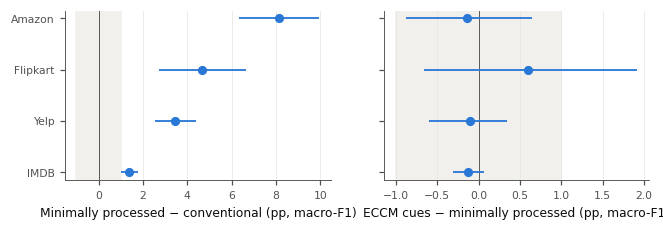


T03_negation_subset_tests: Same comparisons restricted to test reviews with a negation word (NB10 secondary family, Holm over 6)
 dataset     id with without  effect [95% CI] (pp) Holm p                      verdict                  evidence
Flipkart T1-neg   R2      R1 +7.10 [+4.20, +10.02] 0.0012                        HELPS                 Supported
Flipkart T2-neg   R3      R2  +0.45 [-2.07, +2.97] 1.0000         no detectable effect              Inconclusive
    IMDB T1-neg   R2      R1  +1.40 [+0.97, +1.82] 0.0012                        HELPS                 Supported
    IMDB T2-neg   R3      R2  -0.13 [-0.31, +0.06] 0.4980 negligible (CI within ±1 pp) Bounded (CI within ±1 pp)
    Yelp T1-neg   R2      R1  +3.55 [+2.48, +4.64] 0.0012                        HELPS                 Supported
    Yelp T2-neg   R3      R2  -0.05 [-0.73, +0.51] 1.0000 negligible (CI within ±1 pp) Bounded (CI within ±1 pp)


In [5]:
rows, frows = [], []
if have("nb9_res", "nb9_tests"):
    r9, t9 = D["nb9_res"], D["nb9_tests"].set_index("id")
    for tid, lab in [("T1", "Minimally processed − conventional"), ("T2", "ECCM cues − minimally processed")]:
        t = t9.loc[tid]
        frows.append({"dataset": "Amazon", "comparison": lab, "effect_pp": t.effect_pp, "lo_pp": t.lo_pp, "hi_pp": t.hi_pp, "p_holm": t.p_holm,
                      "family": "NB9 text family (4 tests, Holm)", "verdict": t.verdict})
    rows.append({"dataset": "Amazon", "R1 conventional (%)": mstd(r9[r9.model == "R1"].macro_f1), "R2 minimally processed (%)": mstd(r9[r9.model == "R2"].macro_f1),
                 "R3 ECCM cues (%)": mstd(r9[r9.model == "R3"].macro_f1), "ECCM domain anchoring": "active (2 categories)", "source": "NB9 results_per_seed.csv"})
if have("nb10_res", "nb10_tests"):
    r10, t10 = D["nb10_res"], D["nb10_tests"]
    for ds in TEXT_DS:
        rr = r10[r10.dataset == ds]
        rows.append({"dataset": ds, "R1 conventional (%)": mstd(rr[rr.run == "R1"].macro_f1), "R2 minimally processed (%)": mstd(rr[rr.run == "R2"].macro_f1),
                     "R3 ECCM cues (%)": mstd(rr[rr.run == "R3"].macro_f1), "ECCM domain anchoring": "inactive (no categories)", "source": "NB10 results_per_seed.csv"})
        for tid, lab in [("T1", "Minimally processed − conventional"), ("T2", "ECCM cues − minimally processed")]:
            t = t10[(t10.dataset == ds) & (t10.id == tid)].iloc[0]
            frows.append({"dataset": ds, "comparison": lab, "effect_pp": t.effect_pp, "lo_pp": t.lo_pp, "hi_pp": t.hi_pp, "p_holm": t.p_holm,
                          "family": "NB10 primary family (6 tests, Holm)", "verdict": t.verdict})
if rows:
    save_table(pd.DataFrame(rows), "T01_preprocessing_macroF1", "Test macro-F1 (%), mean ± SD over 3 seeds, for R1–R3 on four text datasets",
               "NB9 results_per_seed.csv; NB10 results_per_seed.csv")
if frows:
    FR = pd.DataFrame(frows); FR["evidence"] = FR.verdict.map(status_from)
    FR_out = FR.assign(**{"effect [95% CI] (pp)": [ci_str(a, b, c) for a, b, c in zip(FR.effect_pp, FR.lo_pp, FR.hi_pp)],
                          "Holm p": FR.p_holm.map(lambda x: f"{x:.4f}")})[["dataset", "comparison", "effect [95% CI] (pp)", "Holm p", "family", "verdict", "evidence"]]
    save_table(FR_out, "T02_preprocessing_tests", "Preprocessing effects (test macro-F1, pp) with original 95% CIs, Holm p and test families",
               "NB9 tests.csv (T1, T2); NB10 tests.csv (T1, T2, primary family)",
               note="Amazon tests come from NB9's 4-test text family; Flipkart/IMDB/Yelp from NB10's 6-test family. Bootstrap units: products (Amazon), individual reviews (NB10).")
    order = [d for d in ["Amazon", "Flipkart", "Yelp", "IMDB"] if d in set(FR.dataset)]
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.0), sharey=True)
    for ax, lab in zip(axes, ["Minimally processed − conventional", "ECCM cues − minimally processed"]):
        sub = FR[FR.comparison == lab].set_index("dataset").loc[order]; yv = np.arange(len(order))[::-1]
        ax.axvspan(-1, 1, color=BAND, zorder=0); ax.axvline(0, color=INK2, lw=0.6)
        ax.errorbar(sub.effect_pp, yv, xerr=[sub.effect_pp - sub.lo_pp, sub.hi_pp - sub.effect_pp], fmt="o", color=PAL[0], ecolor=PAL[0], capsize=0, lw=1.2)
        ax.set_yticks(yv); ax.set_yticklabels(order); ax.set_xlabel(f"{lab} (pp, macro-F1)"); ax.grid(axis="x")
    axes[0].set_xlim(left=min(-1.5, FR.lo_pp.min() - 0.5))
    save_fig(fig, "F01_preprocessing_forest", "Effect (pp) with original 95% CIs: left, minimally processed text vs conventional cleaning; right, ECCM cues vs "
             "minimally processed. Shaded band = ±1 pp. One point per dataset.", "NB9 tests.csv; NB10 tests.csv")
if have("nb10_tests"):
    t10 = D["nb10_tests"]; neg = t10[t10.family.str.startswith("secondary")]
    save_table(neg.assign(**{"effect [95% CI] (pp)": [ci_str(a, b, c) for a, b, c in zip(neg.effect_pp, neg.lo_pp, neg.hi_pp)],
                             "Holm p": neg.p_holm.map(lambda x: f"{x:.4f}"), "evidence": neg.verdict.map(status_from)})[
               ["dataset", "id", "with", "without", "effect [95% CI] (pp)", "Holm p", "verdict", "evidence"]],
               "T03_negation_subset_tests", "Same comparisons restricted to test reviews with a negation word (NB10 secondary family, Holm over 6)",
               "NB10 tests.csv (secondary family)", note="Mechanism (negation removal) is a hypothesis; conventional cleaning removes several kinds of information at once.")

## 5. MOSEI and MOSI: baseline comparison with all three inputs (T+A+V)
Fixed model list (no selection): M1 text-only, M2 our adaptation of the paper's RMSR (Eq. 10–14), M3, M4, A2 (M2 + modality dropout),
B3 (M4 with pooled attention), late fusion M1+U3, H2 (classifier head re-fitted on frozen M4 features). Scores are recomputed from the
saved predictions; the interval is descriptive (seed + video bootstrap of the model's own mean, not a test).


T04_mosei_mosi_baselines_full_input: MOSEI and MOSI test macro-F1 and Acc-2 with all inputs (T+A+V), mean ± SD over 3 seeds, fixed model list
dataset                         model macro-F1 (%)     descr. 95% interval (%) Acc-2 non-neutral (%)                   source
  MOSEI                  M1 text-only 63.19 ± 0.37              [61.54, 64.85]          83.85 ± 0.46          NB2 checkpoints
  MOSEI            M2 RMSR adaptation 62.27 ± 0.53              [60.38, 64.00]          82.96 ± 0.27                NB8 preds
  MOSEI                            M3 62.87 ± 1.05              [60.93, 64.71]          83.49 ± 0.39                NB8 preds
  MOSEI                            M4 63.45 ± 0.50              [61.66, 65.14]          83.69 ± 0.48                NB8 preds
  MOSEI    A2 = M2 + modality dropout 62.66 ± 0.35              [60.91, 64.39]          82.74 ± 0.84                NB8 preds
  MOSEI B3 = M4 with pooled attention 63.22 ± 0.59              [61.35, 64.89]          83.47 ± 0.21 

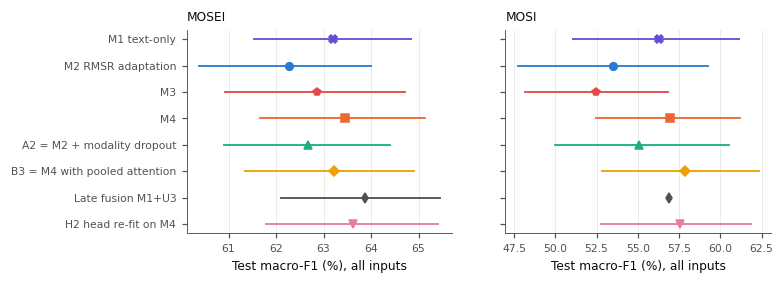


T05a_nb4_dedicated_vs_M4: MOSEI: dedicated unimodal models vs M4 with the same inputs (NB4; Holm over 3 within NB4; exploratory)
modalities  dedicated macro-F1 (fraction)  M4 macro-F1 (fraction)  mean_diff_pp         per_seed_pp seed+video_CI95_pp  seed+video_p  seed+video_p_holm
         A                       0.410615                0.400171      1.044353 +1.18, +1.59, +0.37     [-0.40, +2.46]      0.141986           0.141986
         V                       0.418561                0.394503      2.405841 +2.90, +3.00, +1.32     [+0.74, +4.05]      0.006999           0.020998
       A+V                       0.437431                0.417598      1.983248 +1.60, +2.40, +1.95     [+0.44, +3.63]      0.011799           0.023598

T05b_nb5_late_fusion: MOSEI: late fusion M1+U3 vs M4 and vs M1 (NB5; exploratory, raw p, no multiplicity correction)
   comparison  mean_diff_pp         per_seed_pp  seedvideo_lo_pp  seedvideo_hi_pp  seedvideo_p   correction
LF M1+U3 − M4      0.415684 +0.08, +

In [6]:
BASE_MODELS = [("M1 text-only", "M1"), ("M2 RMSR adaptation", "M2"), ("M3", "M3"), ("M4", "M4"), ("A2 = M2 + modality dropout", "A2"),
               ("B3 = M4 with pooled attention", "B3"), ("Late fusion M1+U3", "LF M1+U3"), ("H2 head re-fit on M4", "H2")]
BL = []
for ds in (["MOSEI", "MOSI"] if preds_ok("NB8") else []):
    if not have(f"nb8_y_{ds.lower()}", f"nb8_ids_{ds.lower()}", f"nb8_score_{ds.lower()}"):
        note("NB8", f"{ds} baseline table", "MISSING", "label/id/score files missing"); continue
    y, g = D[f"nb8_y_{ds.lower()}"], video_groups(ds)
    for name, key in BASE_MODELS:
        probs, src = None, ""
        if key in NB8_MODELS:
            ks = [f"nb8_{ds.lower()}_{key}_{s}" for s in SEEDS]
            if have(*ks):
                probs, src = [D[k]["test_TpApV"] for k in ks], "NB8 preds"
        elif key == "M1":
            nb, fmt = ("NB2", "nb2_M1_{s}") if ds == "MOSEI" else ("NB7", "nb7_M1_{s}")
            if ext_preds(ds, nb, fmt) is not None:
                probs, src = [D[fmt.format(s=s)] for s in SEEDS], f"{nb} checkpoints"
        elif key == "H2":
            nb, fmt = ("NB6", "nb6_H2_{s}") if ds == "MOSEI" else ("NB7", "nb7_H2_{s}")
            if ext_preds(ds, nb, fmt, "T+A+V") is not None:
                probs, src = [D[fmt.format(s=s)]["TpApV"] for s in SEEDS], f"{nb} heads"
        elif key == "LF M1+U3" and ds == "MOSEI":
            if ext_preds(ds, "NB5", "nb5_LF_{s}") is not None:
                probs, src = [D[f"nb5_LF_{s}"] for s in SEEDS], "NB5 LF probabilities"
        if probs is not None:
            preds = [p.argmax(1) for p in probs]; f1s = [f1_score(y, p, average="macro") for p in preds]
            lo, hi = desc_ci(preds, y, g)
            BL.append({"dataset": ds, "model": name, "macro-F1 (%)": mstd(f1s), "descr. 95% interval (%)": f"[{lo:.2f}, {hi:.2f}]",
                       "Acc-2 non-neutral (%)": mstd(acc2(probs, ds)), "source": src, "_key": key, "_mean": 100 * np.mean(f1s), "_lo": lo, "_hi": hi})
        elif key == "LF M1+U3" and ds == "MOSI" and have("nb7_res") and LBL["MOSI"].get("NB7", False):
            v = D["nb7_res"].query("method == 'Late fusion M1+U3' and condition == 'T+A+V'").test_macro_f1
            if len(v) == 3:
                BL.append({"dataset": ds, "model": name, "macro-F1 (%)": mstd(v), "descr. 95% interval (%)": "n/a (predictions not saved)",
                           "Acc-2 non-neutral (%)": "n/a", "source": "NB7 results_per_seed.csv", "_key": key, "_mean": 100 * v.mean(), "_lo": np.nan, "_hi": np.nan})
        else:
            src_nb = {"M1": "NB2" if ds == "MOSEI" else "NB7", "H2": "NB6" if ds == "MOSEI" else "NB7", "LF M1+U3": "NB5" if ds == "MOSEI" else "NB7"}.get(key, "NB8")
            why = "NOT USED (test samples do not match NB8: labels/identifiers)" if src_nb != "NB8" and not LBL[ds].get(src_nb, False) else "SOURCE MISSING"
            BL.append({"dataset": ds, "model": name, "macro-F1 (%)": why, "descr. 95% interval (%)": "", "Acc-2 non-neutral (%)": "",
                       "source": src_nb, "_key": key, "_mean": np.nan, "_lo": np.nan, "_hi": np.nan})
if BL:
    BLT = pd.DataFrame(BL)
    save_table(BLT.drop(columns=[c for c in BLT.columns if c.startswith("_")]), "T04_mosei_mosi_baselines_full_input",
               "MOSEI and MOSI test macro-F1 and Acc-2 with all inputs (T+A+V), mean ± SD over 3 seeds, fixed model list",
               "NB2/NB7 M1 test probabilities; NB8 predictions; NB5 late-fusion probabilities (MOSEI); NB7 results_per_seed.csv (MOSI late fusion); NB6/NB7 H2 heads",
               note="Descriptive intervals, not tests. The saved paired tests between these models are in T07 (NB8), T08 (NB6/NB7) and T05 (NB4/NB5).")
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.4), sharey=True)
    names = [n for n, _ in BASE_MODELS]; yv = np.arange(len(names))[::-1]
    for ax, ds in zip(axes, ["MOSEI", "MOSI"]):
        sub = BLT[BLT.dataset == ds].set_index("model").reindex(names)
        for yy, (nm, row) in zip(yv, sub.iterrows()):
            if np.isnan(row._mean):
                continue
            c, mk = STYLE.get(row._key, (INK2, "o"))
            if not np.isnan(row._lo):
                ax.plot([row._lo, row._hi], [yy, yy], color=c, lw=1.2)
            ax.plot(row._mean, yy, marker=mk, color=c, ms=5, ls="none")
        ax.set_title(ds, loc="left"); ax.set_xlabel("Test macro-F1 (%), all inputs"); ax.grid(axis="x")
    axes[0].set_yticks(yv); axes[0].set_yticklabels(names)
    save_fig(fig, "F02_mosei_mosi_baselines", "Test macro-F1 (%) with all inputs, mean of 3 seeds with descriptive 95% intervals (MOSI late fusion: no interval, "
             "predictions not saved). Fixed model order; no model is highlighted.", "NB2/NB7 M1 probabilities; NB8 predictions; NB5 late fusion (MOSEI); NB7 results_per_seed.csv; NB6/NB7 H2 heads")

if have("nb4_tests"):
    t4 = D["nb4_tests"]
    save_table(t4[["modalities", "dedicated_macro_f1", "M4_subset_macro_f1", "mean_diff_pp", "per_seed_pp", "seed+video_CI95_pp", "seed+video_p", "seed+video_p_holm"]]
               .rename(columns={"dedicated_macro_f1": "dedicated macro-F1 (fraction)", "M4_subset_macro_f1": "M4 macro-F1 (fraction)"}),
               "T05a_nb4_dedicated_vs_M4", "MOSEI: dedicated unimodal models vs M4 with the same inputs (NB4; Holm over 3 within NB4; exploratory)",
               "NB4 expA_dedicated_vs_M4_subset.csv", note="Exploratory: MOSEI test set reused; original columns preserved (scores as fractions, differences in pp).")
if have("nb5_ref"):
    t5 = D["nb5_ref"]
    save_table(t5[["comparison", "mean_diff_pp", "per_seed_pp", "seedvideo_lo_pp", "seedvideo_hi_pp", "seedvideo_p"]].assign(correction="none (raw p)"),
               "T05b_nb5_late_fusion", "MOSEI: late fusion M1+U3 vs M4 and vs M1 (NB5; exploratory, raw p, no multiplicity correction)", "NB5 R_reference_comparisons.csv")

## 6. Missing-modality robustness: every input combination (MOSEI, MOSI) and hidden photos (Amazon)


T06_missing_modality_by_condition: Test macro-F1 (%) for every available input combination, mean ± SD over 3 seeds (Dedicated = separately trained unimodal model, only for its own inputs; — = not applicable)
dataset     model            T            A            V          A+V          T+A          T+V        T+A+V
  MOSEI        M2 61.65 ± 0.24 31.62 ± 5.07 34.08 ± 3.36 36.05 ± 4.18 61.78 ± 0.37 62.35 ± 0.41 62.27 ± 0.53
  MOSEI        M4 62.67 ± 0.38 40.02 ± 0.72 39.45 ± 1.17 41.76 ± 0.42 62.81 ± 0.34 63.57 ± 0.59 63.45 ± 0.50
  MOSEI        A2 61.66 ± 0.69 39.59 ± 0.65 39.15 ± 1.12 41.89 ± 0.10 62.19 ± 0.59 62.56 ± 0.28 62.66 ± 0.35
  MOSEI        B3 62.81 ± 0.29 40.39 ± 0.68 40.29 ± 0.64 42.70 ± 0.66 62.94 ± 0.19 63.48 ± 0.36 63.22 ± 0.59
  MOSEI        H2 62.81 ± 0.59 39.86 ± 0.56 41.17 ± 0.14 43.14 ± 1.37 63.00 ± 0.68 63.88 ± 0.69 63.61 ± 0.73
  MOSEI Dedicated            — 41.06 ± 0.10 41.86 ± 0.78 43.74 ± 0.42            —            —            —
   MOSI        M2 53.79 ± 3.

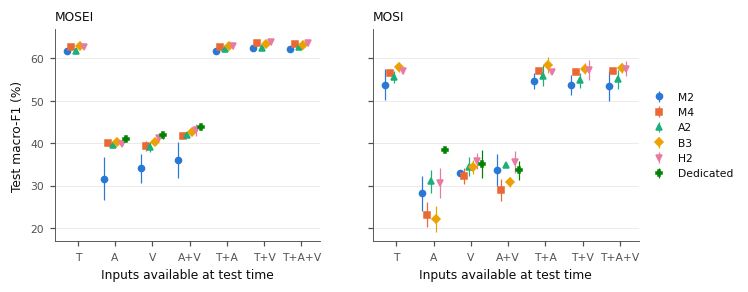


T09_amazon_hidden_photos: Amazon test macro-F1 (%) when photos are hidden for a share of test reviews (same masks for every model; mean ± SD over 3 seeds × mask seeds)
model    0% hidden   30% hidden   50% hidden   70% hidden  100% hidden
  CAT 81.56 ± 0.19 81.49 ± 0.16 81.50 ± 0.21 81.46 ± 0.25 81.50 ± 0.35
   F1 81.98 ± 0.34 81.84 ± 0.25 81.90 ± 0.25 81.86 ± 0.21 81.77 ± 0.30
   F2 82.13 ± 0.31 82.13 ± 0.27 82.13 ± 0.27 82.13 ± 0.27 82.13 ± 0.31
   F3 81.99 ± 0.44 81.99 ± 0.38 81.99 ± 0.38 81.99 ± 0.38 81.99 ± 0.44
  IMG 45.44 ± 1.75 39.59 ± 1.58 35.02 ± 1.41 29.05 ± 0.99 16.47 ± 0.47
 SHUF 82.23 ± 0.35 82.24 ± 0.27 82.30 ± 0.21 82.32 ± 0.20 82.34 ± 0.21


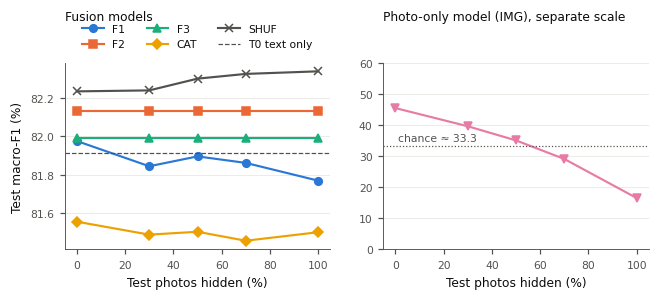

In [7]:
MISS_MODELS = ["M2", "M4", "A2", "B3", "H2", "Dedicated"]
MR = []
for ds in (["MOSEI", "MOSI"] if preds_ok("NB8") else []):
    if not have(f"nb8_y_{ds.lower()}"):
        continue
    y = D[f"nb8_y_{ds.lower()}"]
    for m in ["M2", "M4", "A2", "B3"]:
        for c in CONDS:
            p = mm_preds(ds, m, c)
            if p is not None:
                MR += [{"dataset": ds, "model": m, "condition": c, "seed": s, "macro_f1": f1_score(y, q, average="macro"), "source": "NB8 preds"} for s, q in zip(SEEDS, p)]
    nb, fmt = ("NB6", "nb6_H2_{s}") if ds == "MOSEI" else ("NB7", "nb7_H2_{s}")
    for c in CONDS:
        p = ext_preds(ds, nb, fmt, c) if LBL[ds].get(nb, False) else None
        if p is not None:
            MR += [{"dataset": ds, "model": "H2", "condition": c, "seed": s, "macro_f1": f1_score(y, q, average="macro"), "source": f"{nb} heads"} for s, q in zip(SEEDS, p)]
    nbu = "NB4" if ds == "MOSEI" else "NB7"
    for u, c in [("U1", "A"), ("U2", "V"), ("U3", "A+V")]:
        fmt = f"nb4_{u}_{{s}}" if ds == "MOSEI" else f"nb7_{u}_{{s}}"
        p = ext_preds(ds, nbu, fmt)
        if p is not None:
            MR += [{"dataset": ds, "model": "Dedicated", "condition": c, "seed": s, "macro_f1": f1_score(y, q, average="macro"), "source": f"{nbu} {u}"} for s, q in zip(SEEDS, p)]
if MR:
    MRT = pd.DataFrame(MR)
    tab = MRT.groupby(["dataset", "model", "condition"]).macro_f1.apply(lambda v: mstd(v)).unstack("condition").reindex(columns=CONDS).reset_index()
    tab["model"] = pd.Categorical(tab.model, MISS_MODELS); tab = tab.sort_values(["dataset", "model"])
    tab["model"] = tab["model"].astype(str); tab = tab.fillna("—")      # categorical -> text before filling (pandas 2.2 checks every column)
    save_table(tab, "T06_missing_modality_by_condition", "Test macro-F1 (%) for every available input combination, mean ± SD over 3 seeds "
               "(Dedicated = separately trained unimodal model, only for its own inputs; — = not applicable)",
               "NB8 preds (M2, M4, A2, B3); NB6/NB7 H2 heads; NB4/NB7 dedicated models U1–U3")
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.5), sharey=True)
    present = [m for m in MISS_MODELS if m in set(MRT.model)]; off = np.linspace(-0.3, 0.3, len(present))
    for ax, ds in zip(axes, ["MOSEI", "MOSI"]):
        sub = MRT[MRT.dataset == ds].groupby(["model", "condition"]).macro_f1.agg(["mean", "std"]).reset_index()
        for o, m in zip(off, present):
            s_ = sub[sub.model == m].set_index("condition").reindex(CONDS); xs = np.arange(len(CONDS)) + o
            c, mk = STYLE[m]
            ax.errorbar(xs, 100 * s_["mean"], yerr=100 * s_["std"], fmt=mk, color=c, ms=4, lw=0.8, capsize=0, label=m)
        ax.set_xticks(range(len(CONDS))); ax.set_xticklabels(CONDS); ax.set_title(ds, loc="left"); ax.set_xlabel("Inputs available at test time"); ax.grid(axis="y")
    axes[0].set_ylabel("Test macro-F1 (%)"); axes[1].legend(ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5))
    save_fig(fig, "F03_missing_modality_conditions", "Test macro-F1 (%) by available inputs (mean ± SD over 3 seeds) for M2, M4, A2, B3, the re-fitted head H2 "
             "and dedicated unimodal models (only their own inputs).", "NB8 preds; NB6/NB7 H2 heads; NB4/NB7 dedicated models U1–U3")

if have("nb9_miss"):
    mp = D["nb9_miss"]; m = mp.groupby(["model", "hidden_rate"]).macro_f1.agg(["mean", "std"]).reset_index()
    tab = mp.groupby(["model", "hidden_rate"]).macro_f1.apply(lambda v: mstd(v)).unstack("hidden_rate").reset_index()
    tab.columns = ["model"] + [f"{c}% hidden" for c in tab.columns[1:]]
    save_table(tab, "T09_amazon_hidden_photos", "Amazon test macro-F1 (%) when photos are hidden for a share of test reviews (same masks for every model; "
               "mean ± SD over 3 seeds × mask seeds)", "NB9 missing_photo_per_seed.csv")
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.2))
    fus = [h for h in ["F1", "F2", "F3", "CAT", "SHUF"] if h in set(m.model)]
    fstyle = {"F1": (PAL[0], "o"), "F2": (PAL[1], "s"), "F3": (PAL[2], "^"), "CAT": (PAL[3], "D"), "SHUF": (INK2, "x"), "IMG": (PAL[4], "v")}
    for h in fus:
        s_ = m[m.model == h]; c, mk = fstyle[h]
        axes[0].plot(s_.hidden_rate, 100 * s_["mean"], marker=mk, color=c, label=h)
    if have("nb9_res"):
        t0 = 100 * D["nb9_res"].query("model == 'T0'").macro_f1.mean(); axes[0].axhline(t0, color=INK2, ls="--", lw=0.8, label="T0 text only")
    axes[0].set_xlabel("Test photos hidden (%)"); axes[0].set_ylabel("Test macro-F1 (%)"); axes[0].grid(axis="y")
    axes[0].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02)); axes[0].set_title("Fusion models", loc="left", pad=28)
    if "IMG" in set(m.model):
        s_ = m[m.model == "IMG"]; c, mk = fstyle["IMG"]
        axes[1].plot(s_.hidden_rate, 100 * s_["mean"], marker=mk, color=c); axes[1].axhline(100 / 3, color=INK2, ls=":", lw=0.8)
        axes[1].annotate("chance ≈ 33.3", (0, 100 / 3), xytext=(2, 3), textcoords="offset points", fontsize=7, color=INK2)
        axes[1].set_ylim(0, 60); axes[1].set_title("Photo-only model (IMG), separate scale", loc="left", pad=28)
    axes[1].set_xlabel("Test photos hidden (%)"); axes[1].grid(axis="y")
    save_fig(fig, "F04_amazon_hidden_photos", "Amazon test macro-F1 (%) as the share of hidden test photos grows; left: fusion heads (T0 text-only dashed); "
             "right: photo-only head on its own scale.", "NB9 missing_photo_per_seed.csv; NB9 results_per_seed.csv")

## 7. Architectural ablations (Notebook 8): 13 single-change comparisons, MOSEI primary with MOSI replication


T07_ablation_tests: Effect of each component (with − without), test macro-F1 in pp: P1 = all inputs, P2 = mean of 7 input combinations; MOSEI Holm over 26; MOSI own Holm over 26; replication rule fixed in advance
 id                                       component      measure MOSEI effect [95% CI] (pp) MOSEI Holm p (26)                      verdict          evidence (MOSEI) MOSI effect [95% CI] (pp) MOSI Holm p (26)                       replication MOSI Holm p (repl.)
C01                        Eq. 15 (published) on M2     P1 T+A+V       -0.07 [-0.86, +0.72]             1.000 negligible (CI within ±1 pp) Bounded (CI within ±1 pp)      +1.06 [-1.12, +4.67]            1.000                                 -                   —
C01                        Eq. 15 (published) on M2 P2 mean of 7       -6.97 [-8.25, -5.92]             0.005                        HURTS                 Supported      +0.28 [-1.25, +2.20]            1.000                opposite direction               0.797


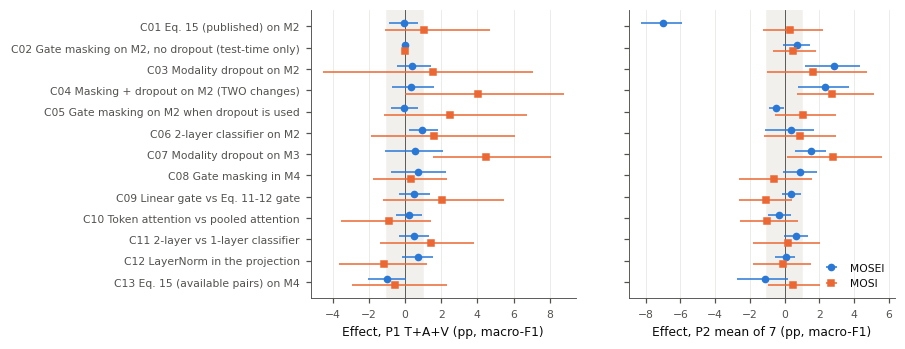


T07b_ablation_secondary_by_condition: Secondary ablation results: each component's effect under each of the 7 input combinations (Holm over 91 within each dataset)
dataset  id                                       component condition    effect [95% CI] (pp) Holm p (91)                      verdict                  evidence
  MOSEI C01                        Eq. 15 (published) on M2         T    -0.08 [-1.03, +0.90]       1.000         no detectable effect              Inconclusive
  MOSEI C01                        Eq. 15 (published) on M2         A -18.37 [-23.09, -14.48]       0.018                        HURTS                 Supported
  MOSEI C01                        Eq. 15 (published) on M2         V -15.22 [-17.94, -12.55]       0.018                        HURTS                 Supported
  MOSEI C01                        Eq. 15 (published) on M2       A+V -14.82 [-16.88, -12.89]       0.018                        HURTS                 Supported
  MOSEI C01                   

In [8]:
if have("nb8_prim"):
    P8 = D["nb8_prim"].copy()
    P8["evidence (MOSEI)"] = P8.verdict.map(status_from)
    cols = ["id", "component", "with", "without", "measure", "effect_pp", "lo_pp", "hi_pp", "p_holm", "verdict", "evidence (MOSEI)"]
    out = P8[cols].copy()
    out["MOSEI effect [95% CI] (pp)"] = [ci_str(a, b, c) for a, b, c in zip(P8.effect_pp, P8.lo_pp, P8.hi_pp)]
    if "MOSI_effect_pp" in P8.columns:
        out["MOSI effect [95% CI] (pp)"] = [ci_str(a, b, c) for a, b, c in zip(P8.MOSI_effect_pp, P8.MOSI_lo_pp, P8.MOSI_hi_pp)]
        out["MOSI Holm p (26)"] = P8.MOSI_p_holm.map(lambda x: f"{x:.3f}"); out["replication"] = P8.replication
        out["MOSI Holm p (repl.)"] = P8.MOSI_p_holm_replication.map(lambda x: "—" if pd.isna(x) else f"{x:.3f}")
    out["MOSEI Holm p (26)"] = P8.p_holm.map(lambda x: f"{x:.3f}")
    keep = ["id", "component", "measure", "MOSEI effect [95% CI] (pp)", "MOSEI Holm p (26)", "verdict", "evidence (MOSEI)"] + \
           [c for c in ["MOSI effect [95% CI] (pp)", "MOSI Holm p (26)", "replication", "MOSI Holm p (repl.)"] if c in out.columns]
    save_table(out[keep], "T07_ablation_tests", "Effect of each component (with − without), test macro-F1 in pp: P1 = all inputs, P2 = mean of 7 input "
               "combinations; MOSEI Holm over 26; MOSI own Holm over 26; replication rule fixed in advance", "NB8 primary_tests.csv",
               note="Replication requires the same sign, |MOSI effect| >= 1 pp and MOSI Holm p < .05 (Holm over the replication tests attempted).")
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 3.4), sharey=True)
    comps = P8.drop_duplicates("id")[["id", "component"]]; yv = np.arange(len(comps))[::-1]
    for ax, meas in zip(axes, ["P1 T+A+V", "P2 mean of 7"]):
        sub = P8[P8.measure == meas].set_index("id").reindex(comps.id)
        ax.axvspan(-1, 1, color=BAND, zorder=0); ax.axvline(0, color=INK2, lw=0.6)
        ax.errorbar(sub.effect_pp, yv + 0.15, xerr=[sub.effect_pp - sub.lo_pp, sub.hi_pp - sub.effect_pp], fmt="o", color=PAL[0], ms=4, lw=1, capsize=0, label="MOSEI")
        if "MOSI_effect_pp" in sub.columns:
            ax.errorbar(sub.MOSI_effect_pp, yv - 0.15, xerr=[sub.MOSI_effect_pp - sub.MOSI_lo_pp, sub.MOSI_hi_pp - sub.MOSI_effect_pp], fmt="s",
                        color=PAL[1], ms=4, lw=1, capsize=0, label="MOSI")
        ax.set_xlabel(f"Effect, {meas} (pp, macro-F1)"); ax.grid(axis="x")
    axes[0].set_yticks(yv); axes[0].set_yticklabels([f"{i} {c}" for i, c in zip(comps.id, comps.component)]); axes[1].legend(loc="lower right")
    save_fig(fig, "F05_ablation_forest", "Effect of each single change (with − without, pp) with original 95% CIs for MOSEI (circles) and MOSI (squares); "
             "left: all inputs; right: mean of 7 input combinations; shaded band = ±1 pp.", "NB8 primary_tests.csv")
if have("nb8_sec"):
    S8 = D["nb8_sec"].copy()
    S8["effect [95% CI] (pp)"] = [ci_str(a, b, c) for a, b, c in zip(S8.effect_pp, S8.lo_pp, S8.hi_pp)]
    S8["Holm p (91)"] = S8.p_holm.map(lambda x: f"{x:.3f}"); S8["evidence"] = S8.verdict.map(status_from)
    save_table(S8[["dataset", "id", "component", "condition", "effect [95% CI] (pp)", "Holm p (91)", "verdict", "evidence"]],
               "T07b_ablation_secondary_by_condition", "Secondary ablation results: each component's effect under each of the 7 input combinations "
               "(Holm over 91 within each dataset)", "NB8 secondary_per_condition.csv")
PARAM_ROWS = []
for ds in ["mosei", "mosi"]:
    if have(f"nb8_params_{ds}"):
        pr = D[f"nb8_params_{ds}"]
        PARAM_ROWS += [{"dataset": ds.upper(), **r} for r in pr[["model", "compared_to", "parameters", "removed", "added", "shape_changed", "modality_dropout", "eq15"]].to_dict("records")]
if PARAM_ROWS:
    save_table(pd.DataFrame(PARAM_ROWS), "T10_mosei_mosi_parameter_counts", "Trainable parameters of every NB8 model and which parameters each variant adds or "
               "removes relative to its reference (latency was not measured for these models)", "NB8 mosei/parameters.csv; NB8 mosi/parameters.csv")

## 8. Classifier adaptation when text is missing (Notebooks 5–7): re-fitting the decision layer on frozen features


T08a_classifier_adaptation_mosei: MOSEI (NB6): re-fitted shared heads H1/H2, FiLM head H3 and separate heads H4 vs M4's own output, test macro-F1 (pp)
condition  comparison effect [95% CI] (pp)         per_seed_pp raw p correction    evidence
        T     H4 − H2 +0.07 [-0.57, +0.76] -0.44, +0.34, +0.30 0.858       none Exploratory
        T     H2 − H1 -0.04 [-0.70, +0.64] +0.48, -0.03, -0.55 0.909       none Exploratory
        T     H3 − H2 +0.01 [-0.63, +0.52] -0.53, +0.19, +0.38 0.900       none Exploratory
        T H1 − M4 own +0.17 [-0.50, +0.83] +0.44, +0.26, -0.19 0.575       none Exploratory
        T H2 − M4 own +0.14 [-0.84, +1.07] +0.92, +0.23, -0.74 0.737       none Exploratory
        T H4 − M4 own +0.20 [-0.61, +0.92] +0.48, +0.57, -0.44 0.548       none Exploratory
        A     H4 − H2 +0.75 [-0.51, +1.94] +0.99, -0.09, +1.37 0.207       none Exploratory
        A     H2 − H1 -0.26 [-1.50, +1.07] -0.74, +0.84, -0.87 0.659       none Exploratory
        A     H3 − H

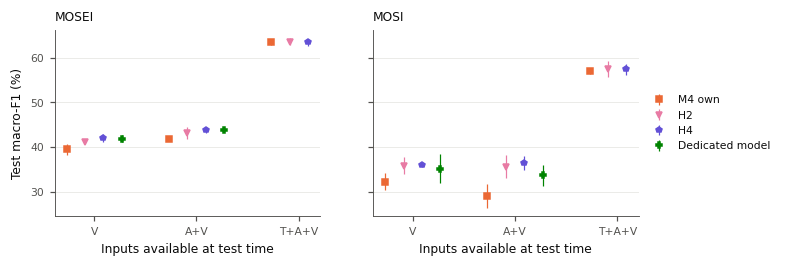

In [9]:
if have("nb6_cmp"):
    c6 = D["nb6_cmp"]
    t = c6.assign(**{"effect [95% CI] (pp)": [ci_str(a, b, c) for a, b, c in zip(c6.mean_diff_pp, c6.sv_lo_pp, c6.sv_hi_pp)],
                     "raw p": c6.sv_p.map(lambda x: f"{x:.3f}"), "correction": "none", "evidence": "Exploratory"})
    save_table(t[["condition", "comparison", "effect [95% CI] (pp)", "per_seed_pp", "raw p", "correction", "evidence"]], "T08a_classifier_adaptation_mosei",
               "MOSEI (NB6): re-fitted shared heads H1/H2, FiLM head H3 and separate heads H4 vs M4's own output, test macro-F1 (pp)",
               "NB6 comparisons.csv", note="Exploratory (MOSEI test reused; no multiplicity correction). NB6's saved verdict label is not used (see validation notes).")
if have("nb7_checks"):
    c7 = D["nb7_checks"]; conf = D.get("nb7_conf") or {}
    t = c7.assign(**{"effect [95% CI] (pp)": [ci_str(a, b, c) for a, b, c in zip(c7.mean_diff_pp, c7.sv_lo_pp, c7.sv_hi_pp)],
                     "raw p": c7.sv_p.map(lambda x: f"{x:.3f}"),
                     "pre-registered verdict": [conf.get(f"{a}_{b}", "") for a, b in zip(c7.check, c7.condition)]})
    hcol = f"Holm p (post hoc, all {len(c7)} NB7 checks)"
    t[hcol] = [f"{NB7_HOLM[(a, b)]:.3f}" for a, b in zip(c7.check, c7.condition)]
    t["evidence"] = [nb7_evidence(c, v, NB7_HOLM[(c, d)]) for c, v, d in zip(t.check, t["pre-registered verdict"], t.condition)]
    narrow = ", ".join(f"{k} {v:.3f}" for k, v in NB7_HOLM_C2_ONLY.items())
    save_table(t[["check", "condition", "comparison", "effect [95% CI] (pp)", "per_seed_pp", "raw p", hcol, "pre-registered verdict", "evidence"]],
               "T08b_classifier_adaptation_mosi", "MOSI (NB7): pre-registered confirmation checks C1–C5, test macro-F1 (pp), with a post-hoc Holm correction",
               "NB7 checks.csv; NB7 CONFIRMATION.json",
               note=f"NB7 rules (fixed before MOSI results) used no multiplicity correction: C1/C2 CONFIRMED = same sign as MOSEI and CI excludes 0; C3 "
                    f"CONFIRMED = H4 − H2 not shown to exceed +1 pp (absence of evidence, labelled Inconclusive); C4 CONFIRMED = point estimate within ±1 pp. "
                    f"The Holm column is a post-hoc correction of NB7's saved raw p-values over all {len(c7)} tests NB7 ran (the convention of NB8–NB10); it is "
                    f"not part of NB7's pre-registered rule. With the narrowest family (C2's two conditions only) Holm p would be: {narrow}. "
                    f"Related published work (e.g. SCBC) exists; its publication details and overlap are not verified.")
AD = []
for ds, nb in [("MOSEI", "nb6_res"), ("MOSI", "nb7_res")]:
    if have(nb):
        r = D[nb]
        for meth in ["M4 own", "H2", "H4", "Dedicated model"]:
            for c in ["V", "A+V", "T+A+V"]:
                v = r[(r.method == meth) & (r.condition == c)].test_macro_f1
                if len(v):
                    AD.append({"dataset": ds, "method": meth, "condition": c, "mean": 100 * v.mean(), "sd": 100 * v.std(ddof=1)})
if AD:
    ADT = pd.DataFrame(AD)
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.2), sharey=True)
    meths = [m for m in ["M4 own", "H2", "H4", "Dedicated model"] if m in set(ADT.method)]
    mstyle = {"M4 own": STYLE["M4"], "H2": STYLE["H2"], "H4": (PAL[6], "p"), "Dedicated model": STYLE["Dedicated"]}
    off = np.linspace(-0.27, 0.27, len(meths))
    for ax, ds in zip(axes, ["MOSEI", "MOSI"]):
        for o, mth in zip(off, meths):
            s_ = ADT[(ADT.dataset == ds) & (ADT.method == mth)].set_index("condition").reindex(["V", "A+V", "T+A+V"])
            c, mk = mstyle[mth]
            ax.errorbar(np.arange(3) + o, s_["mean"], yerr=s_["sd"], fmt=mk, color=c, ms=4, lw=0.8, capsize=0, label=mth)
        ax.set_xticks(range(3)); ax.set_xticklabels(["V", "A+V", "T+A+V"]); ax.set_title(ds, loc="left"); ax.grid(axis="y")
        ax.set_xlabel("Inputs available at test time")
    axes[0].set_ylabel("Test macro-F1 (%)"); axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    save_fig(fig, "F06_classifier_adaptation", "Test macro-F1 (%) (mean ± SD over 3 seeds) for M4's own output, the re-fitted shared head H2, separate heads H4 and "
             "dedicated models, with video only, audio+video, and all inputs.", "NB6 results_per_seed.csv; NB7 results_per_seed.csv")

## 9. Equation 15 alignment and neutral-class predictions (Notebook 8b; associations only)


T11_eq15_criteria: Pre-registered criteria K1–K6 of the Eq. 15 check and the automatic reading (validation set; no training; associations only)
dataset / pair  K1  K2 K3 K4 K5  K6                                                      pre-registered reading
MOSEI A0 vs M2 yes yes no no no yes                   Mixed pattern: see the tables; no single reading applies.
MOSEI B6 vs M4 yes yes no no no yes                   Mixed pattern: see the tables; no single reading applies.
 MOSI A0 vs M2  no  no no no no yes Alignment is not strong (K1 fails): the collapse hypothesis does not apply.
 MOSI B6 vs M4  no  no no no no  no Alignment is not strong (K1 fails): the collapse hypothesis does not apply.

T12_eq15_representations: Representation statistics of audio/video projections (validation, mean of 3 seeds): cosine with text, common-to-specific ratio, pairwise cosine, effective rank, linear read-out r
dataset model modality  cos_with_text  ratio_R  pair_cos  eff_rank  readout_r
  MOSEI    

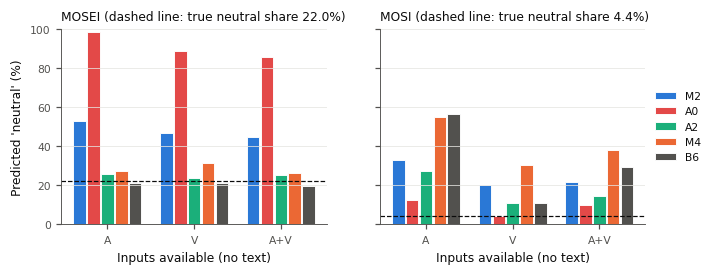

In [10]:
if have("nb8b_check"):
    rows = []
    for k, v in D["nb8b_check"].get("verdicts", {}).items():
        crit = {kk.split()[0]: vv for kk, vv in v["criteria"].items() if not kk.startswith("K6 values")}
        rows.append({"dataset / pair": k.replace("_", " "), **{kk: ("yes" if vv is True else "no" if vv is False else str(vv)) for kk, vv in crit.items()},
                     "pre-registered reading": v["reading"]})
    save_table(pd.DataFrame(rows), "T11_eq15_criteria", "Pre-registered criteria K1–K6 of the Eq. 15 check and the automatic reading (validation set; no training; "
               "associations only)", "NB8b EQ15_CHECK.json", note="K4 can only detect a near-singular projection for M2/A0 (linear projection); causal tests "
               "would require retraining with different lambda1 and were not run.")
REPS = [D[k] for k in ["nb8b_rep_MOSEI", "nb8b_rep_MOSI"] if D.get(k) is not None]
if REPS:
    R = pd.concat(REPS)
    tab = R[R.modality != "text"].groupby(["dataset", "model", "modality"])[["cos_with_text", "ratio_R", "pair_cos", "eff_rank", "readout_r"]].mean().round(3).reset_index()
    save_table(tab, "T12_eq15_representations", "Representation statistics of audio/video projections (validation, mean of 3 seeds): cosine with text, "
               "common-to-specific ratio, pairwise cosine, effective rank, linear read-out r", "NB8b MOSEI_representations.csv; NB8b MOSI_representations.csv")
if have("nb8b_shares"):
    sh = D["nb8b_shares"]; ms = [m for m in ["M2", "A0", "A2", "M4", "B6"] if m in set(sh.model)]
    sub = sh[sh.condition.isin(["A", "V", "A+V", "T+A+V"]) & sh.model.isin(ms)].copy()
    sub["condition"] = pd.Categorical(sub.condition, ["A", "V", "A+V", "T+A+V"]); sub["model"] = pd.Categorical(sub.model, ms)
    tab = sub.groupby(["dataset", "model", "condition"], observed=True)[["neg", "neu", "pos"]].mean()
    save_table((100 * tab).round(1).reset_index().rename(columns={"neg": "negative (%)", "neu": "neutral (%)", "pos": "positive (%)"}),
               "T13_predicted_class_shares", "Share of test predictions per class without text (A, V, A+V) and with all inputs, mean of 3 seeds",
               "NB8b predicted_class_shares.csv")
    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.3), sharey=True)
    w = 0.8 / len(ms)
    for ax, ds in zip(axes, ["MOSEI", "MOSI"]):
        sub = sh[sh.dataset == ds].groupby(["model", "condition"]).neu.mean()
        for i, mdl in enumerate(ms):
            c, _ = STYLE[mdl]
            vals = [100 * sub.get((mdl, c_), np.nan) for c_ in ["A", "V", "A+V"]]
            ax.bar(np.arange(3) - 0.4 + w * (i + 0.5), vals, width=w * 0.9, color=c, label=mdl, edgecolor="white", linewidth=0.6)
        yt = D.get(f"nb8_y_{ds.lower()}"); ttl = ds
        if yt is not None:
            tr = 100 * np.mean(yt == 1); ax.axhline(tr, color=INK, ls="--", lw=0.8); ttl = f"{ds} (dashed line: true neutral share {tr:.1f}%)"
        ax.set_xticks(range(3)); ax.set_xticklabels(["A", "V", "A+V"]); ax.set_title(ttl, loc="left"); ax.set_xlabel("Inputs available (no text)")
        ax.set_ylim(0, 100); ax.grid(axis="y")
    axes[0].set_ylabel("Predicted 'neutral' (%)"); axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    save_fig(fig, "F07_neutral_share_without_text", "Share of test clips predicted 'neutral' when text is missing, per model (mean of 3 seeds); dashed line = true "
             "neutral share. A0 = M2 + Eq. 15 (published form); B6 = M4 + Eq. 15 on available pairs.", "NB8b predicted_class_shares.csv; NB8 test_labels.npy")

## 10. Amazon: photo utility, fairness (product categories) and calibration (Notebook 9)


T14_amazon_all_models: Amazon test results, mean ± SD over 3 seeds (heads use the text backbone chosen on validation: R3)
                      model macro-F1 (%) worst-category F1 (%) category gap (pp)             ECE negation-subset F1 (%)
   R1 conventional cleaning 73.90 ± 0.53          72.78 ± 0.30       2.03 ± 0.73 0.0597 ± 0.0061           70.74 ± 0.61
     R2 minimally processed 82.03 ± 0.25          80.48 ± 0.48       2.92 ± 0.93 0.0522 ± 0.0039           80.49 ± 0.55
                    R3 ECCM 81.90 ± 0.03          80.29 ± 0.33       3.03 ± 0.69 0.0548 ± 0.0041           80.60 ± 0.59
        R4 ECCM + Group-DRO 81.91 ± 0.46          80.40 ± 0.57       2.86 ± 0.23 0.0522 ± 0.0086           80.69 ± 0.59
          T0 text-only head 81.91 ± 0.34          80.20 ± 0.51       3.23 ± 0.60 0.0584 ± 0.0071           80.22 ± 0.45
        IMG photo-only head 45.44 ± 1.75          44.51 ± 1.15       1.90 ± 1.79 0.0345 ± 0.0154           42.49 ± 2.60
          CAT concatenation 81.56 ± 0

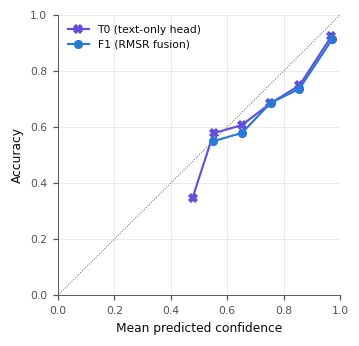

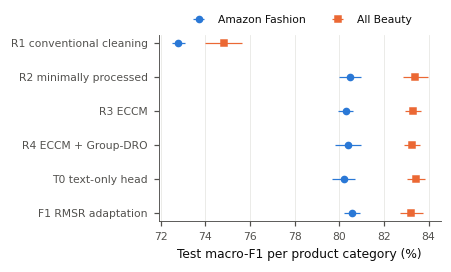

In [11]:
AMZ_ORDER = ["R1", "R2", "R3", "R4", "T0", "IMG", "CAT", "F1", "F2", "F3", "SHUF"]
AMZ_NAME = {"R1": "R1 conventional cleaning", "R2": "R2 minimally processed", "R3": "R3 ECCM", "R4": "R4 ECCM + Group-DRO", "T0": "T0 text-only head",
            "IMG": "IMG photo-only head", "CAT": "CAT concatenation", "F1": "F1 RMSR adaptation", "F2": "F2 token cross-attention", "F3": "F3 pooled attention",
            "SHUF": "SHUF shuffled-photo control"}
if have("nb9_res"):
    r9 = D["nb9_res"]; rows = []
    for m in AMZ_ORDER:
        rr = r9[r9.model == m]
        if len(rr) == 3:
            rows.append({"model": AMZ_NAME[m], "macro-F1 (%)": mstd(rr.macro_f1), "worst-category F1 (%)": mstd(rr.worst_group_f1),
                         "category gap (pp)": mstd(rr.category_gap), "ECE": f"{rr.ece.mean():.4f} ± {rr.ece.std(ddof=1):.4f}", "negation-subset F1 (%)": mstd(rr.negation_f1)})
    sel = (D.get("nb9_sel") or {}).get("selected", "unknown")
    save_table(pd.DataFrame(rows), "T14_amazon_all_models", f"Amazon test results, mean ± SD over 3 seeds (heads use the text backbone chosen on validation: {sel})",
               "NB9 results_per_seed.csv; NB9 text_backbone_selection.json", note="Fairness groups are product categories (Fashion vs Beauty), not groups of people. "
               "The text backbone was chosen on validation by NB9's fixed rule. Split check vs Notebook 1: " +
               next((f"{r['status']}" for r in VAL if r["item"].startswith("Amazon split fingerprint")), "not run") + ".")
if have("nb9_tests"):
    t9 = D["nb9_tests"]; sub = t9[t9.family.isin(["fusion", "secondary"])]
    save_table(sub.assign(**{"effect [95% CI] (pp)": [ci_str(a, b, c) for a, b, c in zip(sub.effect_pp, sub.lo_pp, sub.hi_pp)],
                             "Holm p": sub.p_holm.map(lambda x: f"{x:.3f}"), "evidence": sub.verdict.map(status_from)})[
               ["family", "id", "question", "effect [95% CI] (pp)", "per_seed_pp", "Holm p", "verdict", "evidence"]],
               "T15_amazon_photo_tests", "Amazon photo tests: fusion family (6, Holm) and secondary family (hidden photos, shuffled test photos; Holm within)",
               "NB9 tests.csv", note="Bootstrap unit: products. Text-family tests (T1–T4) are in T02 and T16.")
    tx = t9[t9.family == "text"]
    save_table(tx.assign(**{"effect [95% CI] (pp)": [ci_str(a, b, c) for a, b, c in zip(tx.effect_pp, tx.lo_pp, tx.hi_pp)],
                            "Holm p": tx.p_holm.map(lambda x: f"{x:.3f}"), "evidence": tx.verdict.map(status_from)})[
               ["id", "question", "metric", "effect [95% CI] (pp)", "per_seed_pp", "Holm p", "verdict", "evidence"]],
               "T16_amazon_text_family", "Amazon text family (4 tests, Holm): cleaning, ECCM, Group-DRO macro-F1 and worst-category F1", "NB9 tests.csv")
if have("nb9_split") and all(have(f"nb9_{h}_{s}") for h in ["T0", "F1"] for s in SEEDS) and preds_ok("NB9"):
    y9 = D["nb9_split"].query("split == 'test'").label.values
    fig, ax = plt.subplots(figsize=(SINGLE, SINGLE))
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":")
    rel = []
    for h, (c, mk) in [("T0", (PAL[6], "X")), ("F1", STYLE["M2"])]:
        P = np.concatenate([D[f"nb9_{h}_{s}"]["test_r0"] for s in SEEDS]); yy = np.tile(y9, len(SEEDS))
        conf, corr = P.max(1), (P.argmax(1) == yy).astype(float); bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(conf, bins) - 1, 0, 9)
        for b in range(10):
            if (idx == b).sum() >= 20:
                rel.append({"model": h, "bin": f"{bins[b]:.1f}-{bins[b + 1]:.1f}", "n": int((idx == b).sum()), "mean confidence": conf[idx == b].mean(), "accuracy": corr[idx == b].mean()})
        rr = pd.DataFrame([r for r in rel if r["model"] == h])
        ax.plot(rr["mean confidence"], rr["accuracy"], marker=mk, color=c, label=f"{h} ({'text-only head' if h == 'T0' else 'RMSR fusion'})")
    ax.set_xlabel("Mean predicted confidence"); ax.set_ylabel("Accuracy"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left"); ax.grid()
    pd.DataFrame(rel).to_csv(out_path(TAB, "F08_reliability_data.csv"), index=False)
    save_fig(fig, "F08_amazon_reliability_T0_F1", "Reliability diagram (10 confidence bins, bins with >= 20 predictions; 3 seeds pooled) for the text-only head T0 "
             "and the RMSR fusion head F1 (pre-specified pair: reference vs main fusion). Data: F08_reliability_data.csv.", "NB9 heads/*_probs.npz; NB9 split.csv",
             width="single column")
if have("nb9_res"):
    r9 = D["nb9_res"]; fc = [c for c in r9.columns if c.startswith("f1_")]
    if len(fc) == 2:
        fig, ax = plt.subplots(figsize=(SINGLE, 2.2)); mods = ["R1", "R2", "R3", "R4", "T0", "F1"]; yv = np.arange(len(mods))[::-1]
        for (col, (c, mk)) in zip(fc, [(PAL[0], "o"), (PAL[1], "s")]):
            mean = [100 * r9[r9.model == m][col].mean() for m in mods]; sd = [100 * r9[r9.model == m][col].std(ddof=1) for m in mods]
            ax.errorbar(mean, yv, xerr=sd, fmt=mk, color=c, ms=4, lw=0.8, capsize=0, label=col.replace("f1_", "").replace("_", " "))
        ax.set_yticks(yv); ax.set_yticklabels([AMZ_NAME[m] for m in mods]); ax.set_xlabel("Test macro-F1 per product category (%)"); ax.grid(axis="x")
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
        save_fig(fig, "F09_amazon_category_f1", "Test macro-F1 (%) per product category (mean ± SD over 3 seeds) for the text runs and the T0/F1 heads.",
                 "NB9 results_per_seed.csv", width="single column")

## 11. Parameter counts, measured latency and training time (each protocol reported separately; nothing is combined across protocols)


T17_amazon_params_latency: Amazon parameters at inference and measured latency (ms per review) on NVIDIA L4, batch 64, median of 10 passes
model                        name  params head  params text enc.  params CLIP  params total  ms head  ms text enc.  ms CLIP  ms total
   T0           T0 text-only head         2307         124651782            0     124654089 0.004691      0.864516 0.000000  0.869207
  IMG         IMG photo-only head       197635                 0     87456000      87653635 0.006132      0.000000 0.370476  0.376609
  CAT           CAT concatenation       394243         124651782     87456000     212502025 0.006480      0.864516 0.370476  1.241473
   F1          F1 RMSR adaptation       592387         124651782     87456000     212700169 0.013089      0.864516 0.370476  1.248081
 SHUF SHUF shuffled-photo control       592387         124651782     87456000     212700169 0.012911      0.864516 0.370476  1.247903
   F3         F3 pooled attention       462341         1

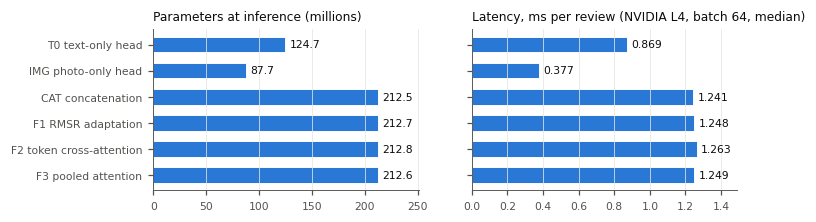


T18_training_time: Measured training time per run, by notebook (different hardware per notebook; not comparable across notebooks)
notebook  dataset                                run                                       hardware  mean training seconds per run  runs
    NB10 Flipkart                                 R1                                      NVIDIA L4                          323.1     3
    NB10 Flipkart                                 R2                                      NVIDIA L4                          322.4     3
    NB10 Flipkart                                 R3                                      NVIDIA L4                          323.9     3
    NB10     IMDB                                 R1                                      NVIDIA L4                          183.7     3
    NB10     IMDB                                 R2                                      NVIDIA L4                          185.7     3
    NB10     IMDB                              

In [12]:
if have("nb9_lat"):
    lat = D["nb9_lat"].copy(); prot = D.get("nb9_latp") or {}
    LAT_COLS = {"head_params": "params head", "text_encoder_params": "params text enc.", "clip_params": "params CLIP", "total_params_at_inference": "params total",
                "ms_per_review_head": "ms head", "ms_per_review_text_encoder": "ms text enc.", "ms_per_review_clip": "ms CLIP", "ms_per_review_total": "ms total"}
    lat_out = lat.rename(columns=LAT_COLS); lat_out.insert(1, "name", lat.model.map(AMZ_NAME))
    save_table(lat_out, "T17_amazon_params_latency", f"Amazon parameters at inference and measured latency (ms per review) on {prot.get('gpu', 'unknown GPU')}, "
               f"batch {prot.get('batch_size_all_components', '?')}, {prot.get('statistic', '?')} of {prot.get('repeats', '?')} passes",
               "NB9 latency_params_b64.csv; NB9 latency_protocol.json", note="ms = milliseconds per review; columns renamed from NB9's file. Excluded: " +
               str(prot.get("excluded", "not recorded")) + ". Latency was not measured for the MOSEI/MOSI models.")
    L = lat.set_index("model"); mods = [m for m in ["T0", "IMG", "CAT", "F1", "F2", "F3"] if m in L.index]
    if mods:
        fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 1.9), sharey=True); yv = np.arange(len(mods))[::-1]
        for ax, col, scale, lab, fmt in [(axes[0], "total_params_at_inference", 1e6, "Parameters at inference (millions)", "{:.1f}"),
                                         (axes[1], "ms_per_review_total", 1, f"Latency, ms per review ({prot.get('gpu', '?')}, batch "
                                          f"{prot.get('batch_size_all_components', '?')}, {prot.get('statistic', '?')})", "{:.3f}")]:
            vals = L.loc[mods, col].values / scale
            ax.barh(yv, vals, height=0.6, color=PAL[0], edgecolor="white", linewidth=0.6)
            for yy, v in zip(yv, vals):
                ax.annotate(fmt.format(v), (v, yy), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7, color=INK)
            ax.set_title(lab, loc="left"); ax.grid(axis="x"); ax.set_xlim(0, vals.max() * 1.18)
        axes[0].set_yticks(yv); axes[0].set_yticklabels([AMZ_NAME[m] for m in mods])
        save_fig(fig, "F10_amazon_params_latency", "Amazon models: parameters used at inference (left) and measured latency per review (right), one protocol "
                 "(NB9). SHUF has the same architecture as F1 (see T17).", "NB9 latency_params_b64.csv; NB9 latency_protocol.json")
def hardware_of(nb):
    out = set()
    for n, rel, key in RUN_KEYS:
        v = D.get(key) or {}
        if n == nb:
            e = v.get("environment", {})
            out.add(v["gpu"] if "gpu" in v else f"CPU: {e.get('cpu', 'model not recorded')}, {e.get('torch_threads', '?')} threads")
    return " | ".join(sorted(out)) or "not recorded"

TT = []
for nb, pat in [("NB2", "nb2_log_M4_"), ("NB9", "nb9_log_"), ("NB10", "nb10_log_")]:
    hw = hardware_of(nb)
    for k, v in D.items():
        if k.startswith(pat) and isinstance(v, dict) and "train_seconds" in v:
            TT.append({"notebook": nb, "dataset": v.get("dataset", "MOSEI" if nb == "NB2" else "Amazon"), "run": v.get("run", v.get("model")), "seed": v.get("seed"),
                       "train_seconds": v["train_seconds"], "hardware": hw})
if TT:
    TTd = pd.DataFrame(TT).groupby(["notebook", "dataset", "run", "hardware"]).train_seconds.agg(["mean", "count"]).round(1).reset_index()
    save_table(TTd.rename(columns={"mean": "mean training seconds per run", "count": "runs"}), "T18_training_time",
               "Measured training time per run, by notebook (different hardware per notebook; not comparable across notebooks)", "training logs of NB2, NB9, NB10")

## 12. Selected confusion matrices (chosen in advance, not by test score)
(a) Amazon R1 vs R2 — the cleaning effect; (b) MOSEI M2 vs A0 vs M4 with audio only — the Eq. 15 neutral shift; (c) Flipkart R1 vs R2.
Row-normalised (each true class sums to 100 %), 3 seeds pooled.

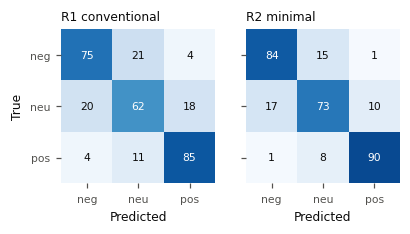

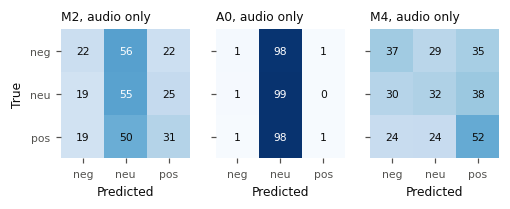

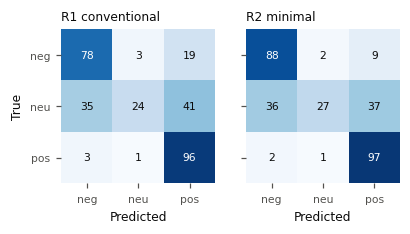

In [13]:
def cm_panel(ax, y, preds, labels, title, first=True):
    cm = sum(confusion_matrix(y, p, labels=range(len(labels))) for p in preds).astype(float)
    cmn = 100 * cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cmn[i, j]:.0f}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 55 else INK)
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels))); ax.set_xticklabels([l[:3] for l in labels])
    ax.set_yticklabels([l[:3] for l in labels] if first else [""] * len(labels))
    ax.set_title(title, loc="left"); ax.set_xlabel("Predicted"); ax.spines[:].set_visible(False)
    return pd.DataFrame(cmn, index=[f"true {l}" for l in labels], columns=[f"pred {l}" for l in labels])

LAB3 = ["negative", "neutral", "positive"]
CMS = {}
if have("nb9_split") and all(have(f"nb9_{r}_{s}") for r in ["R1", "R2"] for s in SEEDS) and preds_ok("NB9"):
    y9 = D["nb9_split"].query("split == 'test'").label.values
    fig, axes = plt.subplots(1, 2, figsize=(SINGLE * 1.2, 1.9))
    for ax, r in zip(axes, ["R1", "R2"]):
        CMS[f"Amazon {r}"] = cm_panel(ax, y9, [D[f"nb9_{r}_{s}"]["probs_test"].argmax(1) for s in SEEDS], LAB3, {"R1": "R1 conventional", "R2": "R2 minimal"}[r], r == "R1")
    axes[0].set_ylabel("True")
    save_fig(fig, "F11a_cm_amazon_R1_R2", "Amazon confusion matrices (row %, 3 seeds pooled): conventional cleaning vs minimally processed text.",
             "NB9 text/R1,R2 *_out.npz; NB9 split.csv", width="single column")
if have("nb8_y_mosei") and all(mm_preds("MOSEI", m, "A") is not None for m in ["M2", "A0", "M4"]) and preds_ok("NB8"):
    fig, axes = plt.subplots(1, 3, figsize=(DOUBLE * 0.75, 1.9))
    for ax, m in zip(axes, ["M2", "A0", "M4"]):
        CMS[f"MOSEI {m} audio only"] = cm_panel(ax, D["nb8_y_mosei"], mm_preds("MOSEI", m, "A"), LAB3, f"{m}, audio only", m == "M2")
    axes[0].set_ylabel("True")
    save_fig(fig, "F11b_cm_mosei_audio_only", "MOSEI confusion matrices with audio only (row %, 3 seeds pooled): M2, A0 (M2 + Eq. 15) and M4.",
             "NB8 mosei/preds; NB8 mosei/test_labels.npy")
if have("nb10_data_Flipkart") and all(have(f"nb10_Flipkart_{r}_{s}") for r in ["R1", "R2"] for s in SEEDS) and preds_ok("NB10"):
    dfk = D["nb10_data_Flipkart"][0]; yk = dfk[dfk.split == "test"].label.values
    fig, axes = plt.subplots(1, 2, figsize=(SINGLE * 1.2, 1.9))
    for ax, r in zip(axes, ["R1", "R2"]):
        CMS[f"Flipkart {r}"] = cm_panel(ax, yk, [D[f"nb10_Flipkart_{r}_{s}"]["test"].argmax(1) for s in SEEDS], LAB3, {"R1": "R1 conventional", "R2": "R2 minimal"}[r], r == "R1")
    axes[0].set_ylabel("True")
    save_fig(fig, "F11c_cm_flipkart_R1_R2", "Flipkart confusion matrices (row %, 3 seeds pooled): conventional cleaning vs minimally processed text.",
             "NB10 Flipkart/R1,R2 *_probs.npz; NB10 Flipkart/data.pkl", width="single column")
if CMS:
    pd.concat(CMS, names=["matrix", "true"]).round(2).to_csv(out_path(TAB, "F11_confusion_matrices_data.csv"))

## 13. Records: dataset sizes, hardware/software, hyperparameters and reproducibility (from saved records only)

In [14]:
def mosi_train_size():
    """MOSI training size is not stored in any result file; read it from the data file NB7 recorded (read only), if present."""
    path = ((D.get("nb7_run") or {}).get("config") or {}).get("DATA_PATH", "")
    if TEST_MODE and os.environ.get("EMOFAR_MOSI"):
        path = os.environ["EMOFAR_MOSI"]
    if not path or not os.path.exists(path):
        note("NB7", "MOSI data file for the training-set size", "MISSING", path or "path not recorded"); return None, "not recorded in saved files"
    register("NB7", path); raw = pickle.load(open(path, "rb")); n = {s: len(raw[s]["regression_labels"]) for s in ("train", "valid", "test")}
    file_ids = [str(x) for x in raw["test"]["id"]]; del raw
    saved = D["nb8_ids_mosi"]["id"].astype(str).tolist() if D.get("nb8_ids_mosi") is not None else None
    ok = saved is not None and file_ids == saved
    note("NB7", "MOSI data file test identifiers = NB8 MOSI test identifiers (same order)", "OK" if ok else "INCONSISTENT", n)
    return (n["train"] if ok else None), f"MOSI data file ({os.path.basename(path)})"

DS_ROWS = []
for ds in ["MOSEI", "MOSI"]:
    yv_, yva = D.get(f"nb8_y_{ds.lower()}"), D.get(f"nb8_yv_{ds.lower()}")
    if yv_ is not None:
        if ds == "MOSEI":
            ntr = next(((D[k].get("v2_train_config") or {}).get("n_train") for k in ["nb6_run", "nb5_run", "nb4_run", "nb3_run"] if D.get(k)), None)
            src_tr = "NB3–NB6 run_info (n_train)"
            if not all(LBL["MOSEI"].values()):
                ntr, src_tr = None, "withheld: NB8 MOSEI test samples do not match NB2–NB6 (labels/identifiers)"
        else:
            ntr, src_tr = mosi_train_size()
        DS_ROWS.append({"dataset": ds, "modalities": "text, audio, video (pre-extracted aligned_50 features)", "train": ntr if ntr else "not recorded",
                        "valid": len(yva) if yva is not None else "not recorded", "test": len(yv_), "test groups": f"{len(set(video_groups(ds)))} videos",
                        "classes (test neg/neu/pos)": "/".join(str(int((yv_ == c).sum())) for c in range(3)), "source": f"NB8 label files; train: {src_tr}"})
if have("nb9_split"):
    sp = D["nb9_split"]
    DS_ROWS.append({"dataset": "Amazon Reviews 2023 (Fashion + Beauty, with photo)", "modalities": "text, photo", **{s: int((sp.split == s).sum()) for s in ["train", "valid", "test"]},
                    "test groups": f"{sp[sp.split == 'test'].parent_asin.nunique()} products",
                    "classes (test neg/neu/pos)": "/".join(str(int(((sp.split == 'test') & (sp.label == c)).sum())) for c in range(3)), "source": "NB9 split.csv"})
for ds in TEXT_DS:
    rep = D.get(f"nb10_val_{ds}")
    if rep:
        cn = rep["counts"]
        DS_ROWS.append({"dataset": ds, "modalities": "text", **{s: sum(cn[s].values()) for s in ["train", "valid", "test"]}, "test groups": "individual reviews",
                        "classes (test neg/neu/pos)": "/".join(str(cn["test"].get(c, "—")) for c in ["negative", "neutral", "positive"]), "source": f"NB10 {ds}/validation_report.json"})
if DS_ROWS:
    save_table(pd.DataFrame(DS_ROWS), "R01_dataset_sizes", "Dataset sizes, splits, test groups and test class counts as recorded by the experiments",
               "NB8 label files; NB9 split.csv; NB10 validation_report.json")
ENV, CONFIGS = [], {}
for nb, rel, key in RUN_KEYS:
    v = D.get(key)
    if not isinstance(v, dict):
        continue
    e = v.get("environment", {}); torch_v = e.get("torch", v.get("torch", "not recorded"))
    gpu = v.get("gpu", "none (CPU build of torch)" if str(torch_v).endswith("+cpu") else "not recorded")
    ENV.append({"notebook": nb, "record": rel, "python": e.get("python", v.get("python", "not recorded")), "torch": torch_v,
                "transformers": v.get("transformers", "—"), "numpy": e.get("numpy", "not recorded"), "scikit-learn": e.get("sklearn", "not recorded"),
                "CPU": e.get("cpu", "not recorded"), "GPU": gpu, "torch threads": e.get("torch_threads", v.get("threads", "not recorded")),
                "OS": e.get("os", "not recorded"), "RAM": "not recorded", "started (UTC)": e.get("started_utc", "not recorded")})
    CONFIGS[f"{nb}/{rel}"] = {k: v[k] for k in v if k != "environment"}
if ENV:
    save_table(pd.DataFrame(ENV), "R02_hardware_software", "Hardware and software recorded by each experiment session (one row per saved run_info file; "
               "resumed runs have several; 'not recorded' = absent from the file)", "run_info*.json of NB2–NB10")
json.dump(CONFIGS, open(out_path(REC, "all_run_configs_verbatim.json"), "w"), indent=2, default=str)
this_run = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
            "os": platform.platform(), "consolidation started (UTC)": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime(T_START))}
json.dump(this_run, open(out_path(REC, "this_consolidation_run.json"), "w"), indent=2)
def flat(cfg, skip=("DATA_PATH", "SEEDS", "SIZES")):
    return "; ".join(f"{k}={v}" for k, v in cfg.items() if k not in skip and not isinstance(v, dict))

HP = []
for nb, key, scope, getter in [("NB2", "nb2_run", "MOSEI", lambda v: v.get("config")), ("NB6", "nb6_run", "MOSEI (v2 settings reused by NB3–NB6)", lambda v: v.get("v2_train_config")),
                               ("NB7", "nb7_run", "MOSI", lambda v: v.get("config"))]:
    c = getter(D.get(key) or {}) if D.get(key) else None
    if c:
        HP.append({"notebook": nb, "scope": scope, "settings (as saved)": flat(c), "seeds": str(c.get("SEEDS", (D[key] or {}).get("seeds", "not recorded"))),
                   "data file": os.path.basename(str(c.get("DATA_PATH", "not recorded")))})
nb8_cfg = next((D[k] for n, r, k in RUN_KEYS if n == "NB8" and D.get(k)), None)
for ds, c in ((nb8_cfg or {}).get("config") or {}).items():
    HP.append({"notebook": "NB8", "scope": ds, "settings (as saved)": flat(c) + f"; lambda1={nb8_cfg.get('lambda1')}", "seeds": str(c.get("SEEDS")),
               "data file": os.path.basename(str(c.get("DATA_PATH")))})
for nb in ["NB9", "NB10"]:
    runs = [D[k] for n, r, k in RUN_KEYS if n == nb and D.get(k)]
    if runs:
        cfgs = {json.dumps(r.get("config"), sort_keys=True) for r in runs}
        if len(cfgs) > 1:
            note(nb, "training settings identical across resumed sessions", "INCONSISTENT", f"{len(cfgs)} different configs")
        c = runs[-1]["config"]
        HP.append({"notebook": nb, "scope": "Amazon text + heads" if nb == "NB9" else "Flipkart, IMDB, Yelp", "settings (as saved)": flat(c),
                   "seeds": str(runs[-1].get("seeds", "not recorded")),
                   "data file": "split.csv (NB9)" if nb == "NB9" else "per-dataset sizes: see records/all_run_configs_verbatim.json"})
if HP:
    save_table(pd.DataFrame(HP), "R03_hyperparameters", "Training settings exactly as saved by each notebook (full records: records/all_run_configs_verbatim.json)",
               "run_info.json of NB2, NB6, NB7, NB8; NB9 and NB10 run logs",
               note="NB2–NB8 code also fixes AdamW (weight decay 1e-4), inverse-frequency class-weighted cross-entropy, gradient clipping at 1.0 and "
                    "early stopping on validation macro-F1; these are in the notebook code, not in the saved settings.")
_v = pd.DataFrame(VAL)
REPRO = [{"check": "Validation of all sources in this notebook", "result": f"{(_v.status == 'OK').sum()} OK, {(_v.status == 'MISSING').sum()} missing, "
          f"{(_v.status == 'INCONSISTENT').sum()} inconsistent, {(_v.status == 'NOTE').sum()} notes", "source": "records/validation_report.csv"}]
if have("nb3_integrity"):
    ic = D["nb3_integrity"]; REPRO.append({"check": "NB3: reloaded v2 checkpoints reproduce saved probabilities", "result": f"max diff {ic.max_abs_prob_diff.max():.2g}; "
                                           f"same predictions {ic.same_predictions.all()}", "source": "NB3 integrity_check.csv"})
for ds in ["mosei", "mosi"]:
    rc = D.get(f"nb8_ref_{ds}")
    if rc:
        REPRO.append({"check": f"NB8 {ds.upper()}: M2 seed 42 retrained bit-identically; references reused", "result": f"identical {rc.get('m2_seed42_identical')}, "
                      f"reuse {rc.get('reuse')}, torch {rc.get('torch')}, cpu {rc.get('cpu')}", "source": f"NB8 {ds}/reference_check.json"})
if have("nb8b_load"):
    REPRO.append({"check": "NB8b: loaded models reproduce NB8 predictions", "result": f"max diff {D['nb8b_load'].max_diff_vs_saved_test_probs.max():.2g}", "source": "NB8b load_checks.csv"})
for r in VAL:
    if r["item"].startswith(("Amazon split fingerprint", "Flipkart split", "IMDB split", "Yelp split")) or "source file hashes" in r["item"] or "recomputed" in r["item"]:
        REPRO.append({"check": f"{r['notebook']}: {r['item']}", "result": f"{r['status']} {r['detail']}", "source": "this notebook"})
REPRO.append({"check": "Seeds", "result": "42, 43, 44 in every experiment (checked above)", "source": "per-seed tables"})
REPRO.append({"check": "RAM of the experiment machines", "result": "not recorded", "source": "—"})
save_table(pd.DataFrame(ALIGN), "R05_sample_alignment", "How the order of test samples was established for every pairing of predictions, labels and "
           "identifiers used here (identifiers compared wherever they were saved)", "test_ids.csv of NB2, NB4–NB8; NB9 split.csv; NB10 data.pkl",
           note="Matching label arrays alone do not establish identical sample order. Where no identifiers were saved, the basis is stated.")
save_table(pd.DataFrame(REPRO), "R04_reproducibility_checks", "Reproducibility and integrity checks taken from saved records", "listed per row")


R01_dataset_sizes: Dataset sizes, splits, test groups and test class counts as recorded by the experiments
                                           dataset                                             modalities  train  valid  test        test groups classes (test neg/neu/pos)                                                  source
                                             MOSEI text, audio, video (pre-extracted aligned_50 features)  16326   1871  4659         676 videos             1350/1025/2284      NB8 label files; train: NB3–NB6 run_info (n_train)
                                              MOSI text, audio, video (pre-extracted aligned_50 features)   1284    229   686          31 videos                 379/30/277 NB8 label files; train: MOSI data file (aligned_50.pkl)
Amazon Reviews 2023 (Fashion + Beauty, with photo)                                            text, photo   8367   1800  1833      1585 products                588/617/628                                     

## 14. Claim-to-evidence table
Each row is a **neutral question**; the result and the evidence label are generated from the saved test files, so the table cannot
state more than the files support. Short labels only — not manuscript text.

In [15]:
def tget(df, **kw):
    if df is None:
        return None
    m = np.ones(len(df), bool)
    for k, v in kw.items():
        m &= (df[k] == v).values
    return df[m].iloc[0] if m.any() else None

def res(r, with_lab):
    """Direction-aware reading of one saved test row (effect = with − without)."""
    v, e = str(r.verdict), r.effect_pp
    if v == "HELPS": return f"{with_lab} higher ({e:+.2f} pp)"
    if v == "HURTS": return f"{with_lab} lower ({e:+.2f} pp)"
    if v.startswith("significant"): return f"significant but below the 1 pp margin ({e:+.2f} pp)"
    if v.startswith("negligible"): return f"difference within ±1 pp ({e:+.2f} pp; bounded, not equivalence)"
    return f"no detectable difference after Holm correction ({e:+.2f} pp)"

def tally(labels):
    c = pd.Series(labels).value_counts()
    return "; ".join(f"{k} ×{v}" if v > 1 else k for k, v in c.items())

CL, HARMFUL = [], []
def claim(cid, question, result, evidence, nb, src, numbers, limitation):
    CL.append({"id": cid, "question": question, "result (from files)": result, "evidence": evidence, "notebook": nb, "source file": src,
               "numerical evidence": numbers, "limitation": limitation})

def multi(cid, question, pairs, with_lab, nb, src, limitation, family):
    pairs = [(l, r) for l, r in pairs if r is not None]
    if not pairs:
        return
    claim(cid, question, "; ".join(f"{l}: {res(r, with_lab)}" for l, r in pairs), tally([status_from(r.verdict) for _, r in pairs]), nb, src,
          "; ".join(f"{l} {ci_str(r.effect_pp, r.lo_pp, r.hi_pp)}, Holm p {r.p_holm:.4f}" for l, r in pairs) + f" [{family}]", limitation)

t10, t9, p8 = D.get("nb10_tests"), D.get("nb9_tests"), D.get("nb8_prim")
AMZ_FP_OK = any(r["item"].startswith("Amazon split fingerprint") and r["status"] == "OK" for r in VAL)
amz_lim = "" if AMZ_FP_OK else " | Amazon split fingerprint did NOT match Notebook 1 (see validation report)"
if t9 is not None or t10 is not None:
    tt = lambda df, i, d=None: None if df is None else (tget(df, id=i) if d is None else tget(df, dataset=d, id=i))
    multi("E1", "Minimally processed text vs conventional cleaning (test macro-F1)", [("Amazon", tt(t9, "T1"))] + [(d, tt(t10, "T1", d)) for d in TEXT_DS],
          "minimally processed", "NB9, NB10", "amazon_v9/tests.csv; text_v10/tests.csv", "NB10 bootstrap resamples individual reviews (no product/business IDs)" + amz_lim,
          "Amazon: NB9 text family, 4 tests; others: NB10 primary family, 6 tests")
    multi("E2", "ECCM cue-based processing vs minimally processed text (test macro-F1)", [("Amazon", tt(t9, "T2"))] + [(d, tt(t10, "T2", d)) for d in TEXT_DS],
          "ECCM", "NB9, NB10", "amazon_v9/tests.csv; text_v10/tests.csv", "'Bounded' is not a formal equivalence test; ECCM domain anchoring inactive on "
          "Flipkart/IMDB/Yelp; this Flipkart copy is not code-mixed" + amz_lim, "same families as E1")
    multi("E3", "Same comparison as E1, test reviews containing a negation word", [(d, tt(t10, "T1-neg", d)) for d in TEXT_DS], "minimally processed", "NB10",
          "text_v10/tests.csv", "Subset vs whole-set difference not tested; negation removal as the mechanism is a hypothesis", "NB10 secondary family, 6 tests")
    multi("E4", "Group-DRO vs standard training (Amazon)", [("macro-F1", tt(t9, "T3")), ("worst-category F1", tt(t9, "T4"))], "Group-DRO", "NB9", "amazon_v9/tests.csv",
          "Two product categories only; fairness group = product category, not people" + amz_lim, "NB9 text family, 4 tests")
    multi("E5", "Photo fusion vs text only, and between fusion designs (Amazon)", [(i, tt(t9, i)) for i in ["P1", "P2", "P3", "P4", "P5", "P6"]], "'with' model",
          "NB9", "amazon_v9/tests.csv (question text per id in T15)", "Frozen encoders for fusion heads; photo-containing reviews only; star-derived labels" + amz_lim,
          "NB9 fusion family, 6 tests")
    multi("E6", "Real vs within-category shuffled test photos; all photos hidden vs none (F1 head)", [("shuffled", tt(t9, "S-F1")), ("hidden", tt(t9, "M-F1"))],
          "real / present photos", "NB9", "amazon_v9/tests.csv (secondary)", "Missing photos are simulated; evaluation-only shuffle" + amz_lim, "NB9 secondary family")
if have("nb9_res"):
    img = D["nb9_res"].query("model == 'IMG'").macro_f1
    claim("E7", "Photo-only head (IMG) test macro-F1", f"{mstd(img)}% (three classes; uniform guessing ≈ 33.3%)", "Descriptive", "NB9", "amazon_v9/results_per_seed.csv",
          f"per seed: {', '.join(f'{100 * v:.2f}' for v in img)}", "No test against chance was pre-registered" + amz_lim)
if have("nb9_lat"):
    L = D["nb9_lat"].set_index("model"); prot = D.get("nb9_latp") or {}
    if {"T0", "F1"} <= set(L.index):
        a, b = L.loc["T0"], L.loc["F1"]
        claim("E8", "Inference cost of photo fusion (F1) vs text only (T0)",
              f"parameters +{100 * (b.total_params_at_inference / a.total_params_at_inference - 1):.0f}%, latency +{100 * (b.ms_per_review_total / a.ms_per_review_total - 1):.0f}%",
              "Descriptive", "NB9", "amazon_v9/latency_params_b64.csv; latency_protocol.json",
              f"{a.total_params_at_inference / 1e6:.1f}M → {b.total_params_at_inference / 1e6:.1f}M parameters; {a.ms_per_review_total:.3f} → {b.ms_per_review_total:.3f} ms/review",
              f"One protocol only: {prot.get('gpu', '?')}, batch {prot.get('batch_size_all_components', '?')}, {prot.get('statistic', '?')}; excluded: {prot.get('excluded', '?')}")
if p8 is not None:
    for cid, comp, q in [("E9", "C03", "Modality dropout on M2 (mean of 7 input combinations)"), ("E10", "C01", "Eq. 15 (published form) on M2 (mean of 7 input combinations)")]:
        r = tget(p8, id=comp, measure="P2 mean of 7")
        if r is not None:
            rep = r["replication"] if "replication" in r.index else "not available"
            claim(cid, q, f"MOSEI: {res(r, 'with the component')}; MOSI replication: {rep}", f"MOSEI: {status_from(r.verdict)}; MOSI: {rep}", "NB8",
                  "v8_ablations/primary_tests.csv", f"MOSEI {ci_str(r.effect_pp, r.lo_pp, r.hi_pp)}, Holm p {r.p_holm:.3f} [26 tests]; MOSI "
                  f"{ci_str(r.MOSI_effect_pp, r.MOSI_lo_pp, r.MOSI_hi_pp)}, own Holm p {r.MOSI_p_holm:.3f}", "MOSEI test set used repeatedly; 3 seeds")
            if comp == "C01" and r.verdict == "HURTS":
                HARMFUL.append((f"Eq. 15 (published form) lowered MOSEI mean-of-7 macro-F1 ({r.effect_pp:+.2f} pp); MOSI: {rep}", "claim E10"))
    arch = p8[p8.id.isin(["C02", "C05", "C06", "C08", "C09", "C10", "C11", "C12"])]
    if len(arch):
        claim("E11", "Single architectural changes between M2 and M4 (masking, gate formula, attention type, classifier depth, LayerNorm)",
              tally([res(a, "with").split(" (")[0] for a in arch.itertuples()]), tally(arch.verdict.map(status_from)), "NB8", "v8_ablations/primary_tests.csv",
              "; ".join(f"{a.id} {a.measure.split()[0]} {a.effect_pp:+.2f}" for a in arch.itertuples()) + " [MOSEI, 26 tests]", "Pre-extracted features; D = 128; 3 seeds")
    r, pm = tget(p8, id="C10", measure="P2 mean of 7"), D.get("nb8_params_mosei")
    if r is not None and pm is not None:
        pp = pm.set_index("model").parameters
        claim("E12", "Token attention (M4) vs pooled attention (B3), with parameter counts", f"{res(r, 'M4 (token)')}; B3 has {100 * (1 - pp['B3'] / pp['M4']):.1f}% fewer parameters",
              status_from(r.verdict), "NB8", "v8_ablations/primary_tests.csv; mosei/parameters.csv",
              f"{ci_str(r.effect_pp, r.lo_pp, r.hi_pp)}, Holm p {r.p_holm:.3f}; parameters B3 {pp['B3']:,} vs M4 {pp['M4']:,}",
              "Not a selection of B3 as the proposed model; latency not measured for these models")
if have("nb7_checks"):
    c7, conf = D["nb7_checks"], D.get("nb7_conf") or {}
    c6 = D.get("nb6_cmp")
    for cid, chk, q, lim in [("E13", "C2", "Re-fitted shared head (H2) on frozen M4 features vs M4's own output, text missing",
                              "Related published work exists (e.g. SCBC); its publication details and methodological overlap are not yet verified — no novelty or priority claim"),
                             ("E14", "C3", "Separate per-combination heads (H4) vs one re-fitted shared head (H2), text missing",
                              "NB7's rule marks CONFIRMED when H4 − H2 is not significant; that is absence of evidence, not equivalence")]:
        rr = c7[c7.check == chk]
        if len(rr):
            mosei = ""
            if c6 is not None:
                cmp = {"C2": "H2 − M4 own", "C3": "H4 − H2"}[chk]
                mosei = "; MOSEI (exploratory): " + ", ".join(f"{x.condition} {x.mean_diff_pp:+.2f} (raw p {x.sv_p:.3f})" for x in c6[(c6.comparison == cmp) & c6.condition.isin(["V", "A+V"])].itertuples())
            claim(cid, q, "; ".join(f"MOSI {x.condition}: {conf.get(f'{chk}_{x.condition}', '')} (raw p {x.sv_p:.3f}; post-hoc Holm p "
                                    f"{NB7_HOLM[(chk, x.condition)]:.3f})" for x in rr.itertuples()),
                  "; ".join(f"MOSI {x.condition}: {nb7_evidence(chk, conf.get(f'{chk}_{x.condition}', ''), NB7_HOLM[(chk, x.condition)])}" for x in rr.itertuples()),
                  "NB7 (NB6)", "mosi_v7_confirmation/checks.csv, CONFIRMATION.json; mosei_v6_head_vs_exposure/comparisons.csv",
                  "; ".join(f"MOSI {x.condition} {ci_str(x.mean_diff_pp, x.sv_lo_pp, x.sv_hi_pp)}, raw p {x.sv_p:.3f}, Holm p {NB7_HOLM[(chk, x.condition)]:.3f} "
                            f"[post hoc, all {len(c7)} NB7 checks]" for x in rr.itertuples()) + mosei,
                  lim + ("; NB7's own rule had no multiplicity correction — the Holm adjustment is post hoc" if chk == "C2" else ""))
if have("nb4_tests"):
    t4 = D["nb4_tests"].to_dict("records")
    claim("E15", "Dedicated unimodal models vs M4 with the same non-text inputs (MOSEI)", "; ".join(f"{r['modalities']}: {r['mean_diff_pp']:+.2f} pp" for r in t4),
          "Exploratory", "NB4", "mosei_v4_capacity_utility/expA_dedicated_vs_M4_subset.csv",
          "; ".join(f"{r['modalities']} {r['seed+video_CI95_pp']}, Holm p {r['seed+video_p_holm']:.3f}" for r in t4) + " [Holm over 3 within NB4]",
          "MOSEI test reused; MOSI check C1: " + ", ".join(f"{k[3:]} {v}" for k, v in (D.get("nb7_conf") or {}).items() if k.startswith("C1")))
if have("nb8b_check"):
    for pair in ["MOSEI_A0_vs_M2", "MOSI_A0_vs_M2"]:
        v = D["nb8b_check"]["verdicts"].get(pair)
        if v is None:
            continue
        crit = ", ".join(f"{k.split()[0]} {'yes' if x is True else 'no' if x is False else x}" for k, x in v["criteria"].items() if not k.startswith("K6 values"))
        sh = D.get("nb8b_shares"); neu = ""
        if sh is not None:
            ds = pair.split("_")[0]; g = sh[(sh.dataset == ds) & sh.condition.isin(["A", "V", "A+V"])].groupby(["model", "condition"]).neu.mean()
            neu = "; neutral share A0 vs M2: " + ", ".join(f"{c} {100 * g.get(('A0', c), np.nan):.0f}% vs {100 * g.get(('M2', c), np.nan):.0f}%" for c in ["A", "V", "A+V"])
        claim("E16" + ("a" if pair.startswith("MOSEI") else "b"), f"Eq. 15 and audio/video alignment, collapse and neutral-heavy output without text ({pair.split('_')[0]})",
              v["reading"], "Hypothesis / association (pre-registered criteria)", "NB8b", "v8_ablations/eq15_check/EQ15_CHECK.json; predicted_class_shares.csv",
              crit + neu, D["nb8b_check"].get("note", "Associations only"))
if have("nb3_gate"):
    g = D["nb3_gate"].query("model == 'M4'").groupby("modality").mean_gate_weight.mean()
    claim("E17", "Mean fusion-gate weight per modality in M4 (MOSEI)", ", ".join(f"{k} {v:.3f}" for k, v in g.items()), "Descriptive (exploratory)", "NB3",
          "mosei_v3_diagnostics/gate_vs_utility.csv", "mean over seeds and test clips", "A gate weight is not a measure of causal contribution")
claim("E18", "Can the base paper's Amazon data be rebuilt from its stated link?", "Linked Kaggle set (bittlingmayer/amazonreviews) is binary and text-only; the paper "
      "describes text + image, 3 classes", "Documented check (not an experiment)", "—", "docs/dataset_access.md (checked 22 Nov 2026)",
      "sample download / web check", "The opendatabay link was not independently confirmed; re-check the paper's own wording before citing")
rep_ok = [r for r in VAL if ("recomputed" in r["item"] or "reproduce" in r["item"])]
claim("E19", "Do saved scores and models reproduce from the saved predictions and checkpoints?", tally([r["status"] for r in rep_ok]) if rep_ok else "no checks run",
      "Descriptive (integrity)", "NB3, NB8, NB8b, this notebook", "R04_reproducibility_checks", "; ".join(f"{r['notebook']} {r['item']}: {r['status']}" for r in rep_ok)[:400],
      "Checks one seed per dataset for recomputation; NB8 bit-identity checked for M2 seed 42 only")
CLT = pd.DataFrame(CL)
save_table(CLT, "C01_claim_to_evidence", "Each tested question with its result and evidence label generated from the source files, the notebook, file, numbers and limitation",
           "NB3, NB4, NB6, NB7, NB8, NB8b, NB9, NB10 (file per row)", note="Evidence labels as defined at the top of Notebook 11. 'Bounded' and 'Inconclusive' are not evidence of no effect.")
for r in CL:
    if r["id"] == "E1" and "Supported" in r["evidence"]:
        HARMFUL.append(("Conventional cleaning (paper-style preprocessing) scored lower than minimally processed text — " + r["evidence"] + ": " + r["result (from files)"], "claim E1"))


C01_claim_to_evidence: Each tested question with its result and evidence label generated from the source files, the notebook, file, numbers and limitation
  id                                                                                                            question                                                                                                                                                                                                                                                                                                                                                                               result (from files)                                                                                                                                                                  evidence                      notebook                                                                                   source file                                            

## 15. Limitations, null/negative results and unresolved questions (structured list, not prose)
Design limitations are facts about how the experiments were set up (counts are read from the files). Null and negative results are
**generated from the claim table**, not typed in.

In [16]:
LIM = []
sp = D.get("nb9_split")
amz_n = f"{len(sp):,} reviews" if sp is not None else "size not available"
yelp = (D.get("nb10_val_Yelp") or {}).get("counts", {}).get("test")
yelp_bal = "/".join(f"{100 * yelp.get(c, 0) / sum(yelp.values()):.0f}" for c in ["negative", "neutral", "positive"]) if yelp else "not available"
for item, src in [("3 seeds per configuration; seed variance is part of every interval", "all"),
                  ("MOSEI test set examined repeatedly in NB2–NB8; MOSEI-only effects are partly exploratory", "NB2–NB8"),
                  (f"MOSI test set is small ({len(D['nb8_y_mosi']) if D.get('nb8_y_mosi') is not None else '?'} clips); wide intervals", "NB7, NB8"),
                  ("MOSEI/MOSI audio and video features are word-aligned to the transcript, so 'text missing' still assumes a transcript existed", "aligned_50 features"),
                  (f"Amazon: photo-containing reviews only, star-derived labels, balanced classes, simulated missing photos, {amz_n}", "NB9"),
                  ("Amazon fusion heads use frozen encoders; the published EMO-FAR model (its encoders and its latency/fairness losses) was not reproduced", "NB9"),
                  ("Fairness measured across two product categories only, not across groups of people", "NB9"),
                  ("NB10 bootstrap resamples individual reviews (no product or business IDs in the data); intervals may be too narrow", "NB10"),
                  (f"Flipkart copy is mostly English (not code-mixed); Yelp test class balance {yelp_bal} (neg/neu/pos %); IMDB has two classes; "
                   "ECCM domain anchoring inactive on these three", "NB10 validation reports; project doc notebook10-design"),
                  ("Latency measured only for the Amazon models, under one protocol; no latency for MOSEI/MOSI models", "NB9"),
                  ("RAM of the experiment machines was not recorded", "run_info files"),
                  ("Eq. 15 analysis is associational; criterion K4 can only detect a near-singular projection for M2/A0", "NB8b"),
                  ("Amazon and NB10 prediction files store no sample identifiers; their order rests on the saved row order (asserted at run time in NB9) "
                   "and exact recomputation of saved scores, not on identifier matching", "R05"),
                  ("NB7 had no multiplicity correction in its pre-registered rule; the Holm correction applied here is post hoc", "T08b")]:
    LIM.append(("Design limitation", item, src))
if not AMZ_FP_OK:
    LIM.append(("Data check failed", "Amazon split fingerprint did not match Notebook 1 — Amazon outputs are internally consistent but not the NB1 split", "validation report"))
for r in CL:
    if r["evidence"].startswith(("Descriptive", "Documented", "Hypothesis", "Exploratory")):
        continue
    if "Supported" not in r["evidence"]:
        LIM.append(("Null, bounded or inconclusive result", f"{r['question']}: {r['evidence']}", f"claim {r['id']}"))
    elif any(s in r["evidence"] for s in ("Inconclusive", "Bounded", "Nominal only")):
        LIM.append(("Partly supported result", f"{r['question']}: {r['evidence']}", f"claim {r['id']}"))
for h, src in HARMFUL:
    LIM.append(("Negative result for a base-paper component", h, src))
rep9 = next((r["result (from files)"].split("MOSI replication: ")[-1] for r in CL if r["id"] == "E9"), "not available")
for item, src in [(f"Replication of the C03 modality-dropout effect beyond MOSEI (MOSI status: {rep9})", "NB8"),
                  ("Cause of Eq. 15's effect without text — would need a lambda1 sweep with retraining (not run)", "NB8b"),
                  ("Whether ECCM helps on genuinely code-mixed review text (not tested)", "NB10"),
                  ("Whether the photo helps when the review text is very short or ambiguous (not tested)", "NB9"),
                  ("Overlap of the head re-fit result with published work (e.g. SCBC) — verify publication details and method before any claim", "NB6, NB7")]:
    LIM.append(("Unresolved question", item, src))
LIM.append(("Note", "NB6's saved verdict label 'EXPOSURE EXPLAINS IT' does not match its own numbers; the comparisons are used, the label is not", "NB6"))
save_table(pd.DataFrame(LIM, columns=["category", "item", "source"]), "L01_limitations_negatives_unresolved",
           "Design limitations, null/negative results (generated from C01) and unresolved questions, each with its source", "C01; NB7, NB8, NB9, NB10 records (file per row)")


L01_limitations_negatives_unresolved: Design limitations, null/negative results (generated from C01) and unresolved questions, each with its source
                                  category                                                                                                                                                                                                                                                                                                  item                                                 source
                         Design limitation                                                                                                                                                                                                                                    3 seeds per configuration; seed variance is part of every interval                                                    all
                         Design limitation                         

## 16. Index of every exported file

In [17]:
for f_, what, src in [("records/validation_report.csv", "Validation status of every source file and check", "this notebook"),
                      ("records/source_manifest.csv", "Every source file read, with size, MD5 and modification time", "this notebook"),
                      ("records/this_consolidation_run.json", "Software of this consolidation run (not the experiment machines)", "this notebook"),
                      ("tables/F08_reliability_data.csv", "Data behind figure F08", "NB9"), ("tables/F11_confusion_matrices_data.csv", "Data behind figures F11a–c", "NB8, NB9, NB10")]:
    if os.path.exists(os.path.join(OUT, f_)):
        INDEX.append({"id": os.path.basename(f_).split(".")[0], "type": "record" if f_.startswith("records") else "figure data", "files": f_,
                      "what_it_shows": what, "sources": src, "layout": "—"})
VALT = pd.DataFrame(VAL).drop_duplicates()        # notes added by later sections are included in the final report
VALT.to_csv(out_path(REC, "validation_report.csv"), index=False); pd.DataFrame(MANIFEST).drop_duplicates().to_csv(out_path(REC, "source_manifest.csv"), index=False)
PROB_NB = sorted(set(VALT[VALT.status.isin(["MISSING", "INCONSISTENT"])].notebook))
def idx_status(src):
    hit = [nb for nb in PROB_NB if re.search(rf"\b{nb}\b", str(src))]
    return "OK" if not hit else "CHECK: missing/inconsistent inputs in " + ", ".join(hit) + " (see records/validation_report.csv)"
IDX = pd.DataFrame(INDEX); IDX["validation status"] = IDX.sources.map(idx_status)
IDX.to_csv(out_path(OUT, "INDEX.csv"), index=False)
with open(out_path(OUT, "INDEX.md"), "w") as f:
    f.write("# Notebook 11 exports\n\nFigures: vector PDF + 300-DPI PNG, sized for the Springer Nature template (single column 84 mm, double column 174 mm).\n"
            "Tables: CSV + LaTeX. Add to the preamble: \\usepackage{booktabs,tabularx,xltabular,rotating,pdflscape,graphicx}. "
            "The 'layout' column says how each table is set (portrait, landscape, or breaking across pages). "
            "Every LaTeX caption is a placeholder (TODO) for your own text.\n"
            "Every figure has a matching table or data CSV (table view).\n\n| id | type | files | what it shows | sources | layout | validation status |\n|---|---|---|---|---|---|---|\n")
    for r in IDX.itertuples():
        f.write(f"| {r.id} | {r.type} | {r.files} | {r.what_it_shows} | {r.sources} | {r.layout} | {r._7} |\n")
probs_left = VALT[VALT.status.isin(["MISSING", "INCONSISTENT"])]
print(f"\nExported {sum(IDX.type == 'figure')} figures, {sum(IDX.type == 'table')} tables and {sum(~IDX.type.isin(['figure', 'table']))} records to {OUT}")
print(f"Source checks: {(VALT.status == 'OK').sum()} OK, {len(probs_left)} missing/inconsistent (listed in records/validation_report.csv). "
      f"Run time {time.time() - T_START:.0f}s.")
if len(probs_left):
    print("Outputs needing these sources were skipped:"); print(probs_left[["notebook", "item", "status"]].to_string(index=False))


Exported 13 figures, 28 tables and 5 records to /content/drive/MyDrive/emofar_results/final_v11
Source checks: 347 OK, 0 missing/inconsistent (listed in records/validation_report.csv). Run time 185s.
